# 10 — Deep dive: designs, topics over time, and votes

**Preliminary — for the analysis chapter's deep dive, after notebooks 07 (A6), 08 (A7) and 09 (A8).**

The same speeches as notebooks 07–09: the `d100k` run (S19, P8), floor speeches scored for
ideology (−1 liberal … +1 conservative) and tone (0 neutral … 1 hostile) by
DeepSeek-V4.1-Flash-1017 alone, with speech type and topic from the label run (L1–L8, **not
yet hand-checked**, L4). `df` is substantive speech (A3); topics exist only on policy
debates (`policy`). The run ids sit in the first code cell; the last Congress, the last
complete Congress and the end date are read from the data. Analysis 10 adds Voteview's roll
calls (Lewis, Poole, Rosenthal, Boche, Rudkin and Sonnet, voteview.com/data, downloaded
2026-11-03), cut at 2025-12-31 as the corpus is (D15).

| # | Analysis | Question | Design |
|---|---|---|---|
| 1 | Do the policy blocks differ? | Did the four policy blocks really change by different amounts? | Joint and pairwise tests in 09's topic model |
| 2 | Which topic carried the growth, and when? | Which block drove the gap at each step, and in which periods? | Agenda/positions split for every Congress-to-Congress step |
| 3 | A majority lost in one chamber | Does losing a chamber change how a party's members speak? | Difference-in-differences: same party, other chamber |
| 4 | Changes of the White House | Does the party that loses the White House move, beyond the winner? | Stacked event study, k = −2 … +1 |
| 4b | The power ladder | Is a party with neither the White House nor its chamber's majority harsher than its two single losses predict? | Model C with four power levels; interaction test |
| 4c | After elections | Does the side that lost an election react harder in the lame duck, and more so over the years? | Before/after within members, losers against winners |
| 5 | Naming the other party | Is naming the other party a matter of the chamber minority or of opposition? | Model C on the 0/1 flag |
| 6 | Swing states, signed | Are senators from their party's strongholds further out, also within the same senator? | Own-party margin; senator fixed effects |
| 7 | Topic blocks around events | Which blocks moved around each event, in agenda, gap and tone? | Before/after per block, as 09's events |
| 8 | New against continuing members | Do newcomers stand out against those already there? | Within party × chamber × Congress |
| 9 | The centre disappears | How fast does the share of members near the centre fall? | Shares at three bands, member bootstrap |
| 10 | Votes across party lines, and votes to undo | Do roll calls show the same split, and more votes to undo after a change? | Voteview roll calls |

Logic in `code/src/deep_dive.py`, figures in `code/src/deep_dive_plots.py` (tested in
`code/tests/test_deep_dive.py`). Figures `results/plots/deepdive_*.png`, tables
`results/metrics/deepdive_*_<RUN>.csv`, all written in the last cell, which refuses to
overwrite an existing file. House and Senate are never pooled (O8) — analysis 3 is the
one place both chambers enter one model, and why that is compatible with O8 is said there.
Every interval is clustered by member; bootstraps draw members within party (1,000 draws,
seed 42).

**Open point:** the dashed line at the 2016-09-10 source change stays in every time plot
for now, as in notebooks 08 and 09; the team will remove it in `plots.py` and CLAUDE.md,
and this notebook will then be rerun (see `deepdive_decisions_draft.md`). Roll calls are
not affected by the source change; their plots carry the line only for consistency.

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "code"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import (
    add_background,
    attach_labels,
    cell_means,
    load_scored_run,
    member_background,
    member_trajectories,
    party_gap,
    relative_to_cell,
    speech_texts,
    substantive,
    toward_party,
)
from src.config import METRICS_DIR, PLOTS_DIR, SCORES_DIR
from src.deep_dive import (
    DEEP_DIVE_BOOTSTRAP,
    EVENT_MIN_DAYS,
    MEMBER_MIN_SPEECHES,
    ROLLCALL_UNDO_DEFINITION,
    TOPIC_MIN_CELL,
    VALUES,
    add_chamber_control,
    add_own_margin,
    bootstrap_step_decomposition,
    centrist_table,
    chamber_flip_cases,
    chamber_flip_data,
    chamber_flip_did,
    chamber_membership,
    cohort_extremity,
    cohort_vs_continuing,
    consecutive_steps,
    cra_resolutions,
    event_block_cell_sizes,
    event_block_effects,
    event_windows,
    fit_topic_model,
    flag_rollcall_undo,
    flag_small_block_cells,
    gap_decomposition,
    is_final_passage,
    keyword_hits,
    keyword_precision,
    last_complete_congress,
    load_corpus_keyword_hits,
    load_rollcall_votes,
    load_rollcalls,
    measure_gap_correlation,
    names_power_effects,
    own_margin_effects,
    own_margin_within,
    party_own_paths,
    period_sums,
    policy_block_tests,
    prior_service_switchers,
    read_keyword_check,
    rollcall_keyword_sample,
    rollcall_party_votes,
    rollcall_summary,
    rollcall_undo_summary,
    state_leans,
    state_margins,
    state_two_party_share,
    step_periods,
    swing_state_effects,
    topic_cell_sizes,
    vote_question_counts,
    voteview_caucus_party,
    wh_event_study,
    wh_event_study_data,
    white_house_changes,
    write_keyword_check,
)
from src.deep_dive_plots import (
    plot_block_differences,
    plot_did_cases,
    plot_event_block_grid,
    plot_event_study,
    plot_own_margin,
    plot_rollcall_lines,
    plot_rollcall_undo,
    plot_steps_decomposition,
    plot_term_coefficients,
)
from src.plots import plot_party_positions, plot_party_positions_by_group, save_figure
from src.runs import run_models

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

RUN = "20261018T122536Z"        # d100k, DeepSeek only (S19)
LABEL_RUN = "20261017T182223Z"  # speech type and topic (L8)

everything = attach_labels(load_scored_run(RUN), LABEL_RUN).dropna(subset=["ideology"])
df = substantive(everything).reset_index(drop=True)  # A3: procedural, ceremonial left out
df = add_chamber_control(df).assign(
    extremity=lambda f: toward_party(f),             # R as scored, D sign-flipped
    opposition=lambda f: f["in_opposition"].astype(float),
)
policy = df[df["speech_type"] == "policy_debate"]   # only policy debates carry a topic
(MODEL,) = run_models(SCORES_DIR, RUN)

END_DATE = pd.to_datetime(df["date"]).max().date()
FIRST_CONGRESS = int(df["congress_number"].min())
LAST_CONGRESS = int(df["congress_number"].max())
LAST_COMPLETE = last_complete_congress(END_DATE)
CONGRESSES = range(FIRST_CONGRESS, LAST_CONGRESS + 1)
INCOMPLETE = LAST_CONGRESS if LAST_COMPLETE < LAST_CONGRESS else None
tables = {}   # saved at the end as deepdive_<name>_<RUN>.csv
figures = {}  # saved at the end as deepdive_<name>.png
timings = {}  # bootstrap and loading times
print(f"Model {MODEL}: {len(everything):,} scored speeches; {len(df):,} substantive; "
      f"{len(policy):,} policy debates")
print(f"Scores end {END_DATE}: Congresses {FIRST_CONGRESS}-{LAST_CONGRESS}, "
      f"last complete {LAST_COMPLETE}")

Model deepseek-flash: 99,993 scored speeches; 71,121 substantive; 67,150 policy debates
Scores end 2025-12-18: Congresses 107-119, last complete 118


In [2]:
def with_ci(table, value="mean", digits=2):
    '''"0.46 [0.35, 0.57]" -- a value with its 95% interval.'''
    return table.apply(
        lambda r: f"{r[value]:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]",
        axis=1,
    )


def pct(table, value="value", digits=1):
    '''"12.3% [10.1, 14.5]" -- a share with its 95% interval, in percent.'''
    return table.apply(
        lambda r: f"{100 * r[value]:.{digits}f}% [{100 * r['ci_low']:.{digits}f}, {100 * r['ci_high']:.{digits}f}]",
        axis=1,
    )


def timed(name, function, *args, **kwargs):
    '''Run a slow step and record how long it took.'''
    start = time.time()
    result = function(*args, **kwargs)
    timings[name] = time.time() - start
    print(f"{name}: {timings[name] / 60:.1f} min")
    return result


def keep(fig, name):
    '''Show a figure now; it is saved with the tables in the last cell.'''
    figures[name] = fig
    plt.show()


SUB = "Labels not yet hand-checked. Preliminary."

# Part I — Topics over time

## 1. Do the four policy blocks really differ?

**Question.** Notebook 09 found the gap widening in every block from the 107th to the last
Congress. Did the four policy blocks — economic, social-cultural, security-foreign,
governance — widen by *different* amounts, and which pairs differ?

**How.** 09's saturated topic model (party × block × Congress per chamber, policy debates,
clustered by member) and its change in R − D from the 107th to the last Congress (main) and
to the last complete one (control). New: one joint Wald test that the four policy blocks
changed alike (df = 3; "other" is a remainder, not a policy area, and stays out), and all
six pairwise differences with Holm-adjusted p-values. The same for tone, per party, from
09's tone model. The block changes must reproduce 09's
`deepdive_topic_gap_tests_to_last` and `deepdive_tone_topic_tests` exactly.

Block changes reproduce notebook 09 (gap and tone).


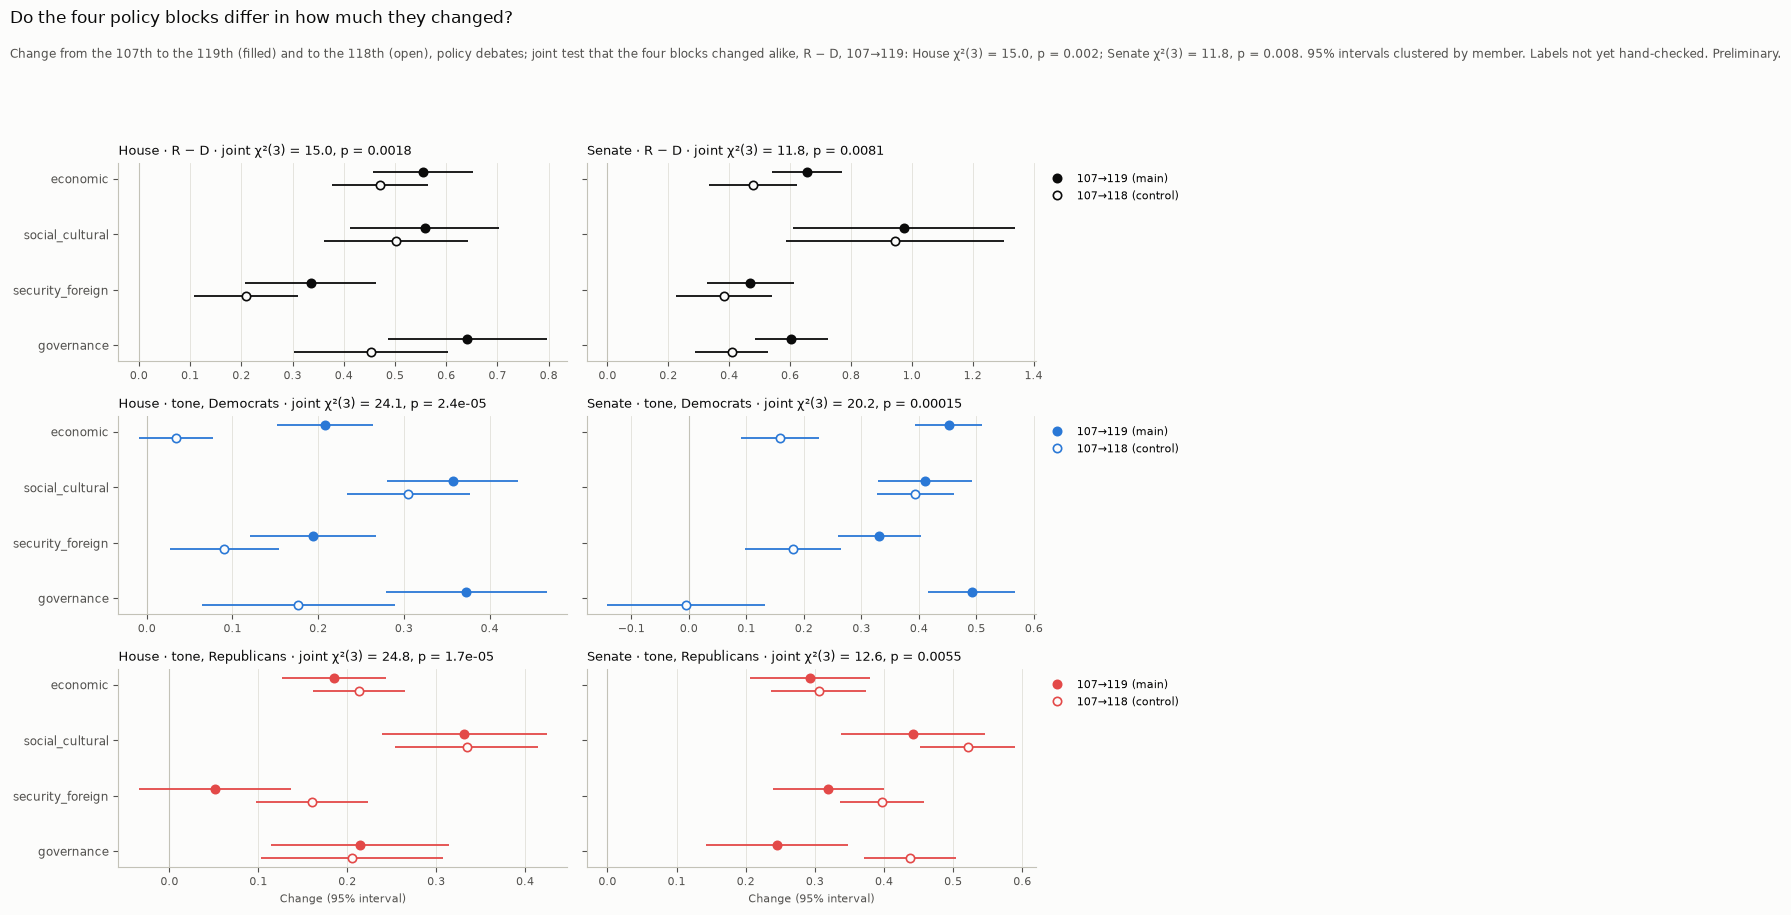

In [3]:
sizes = topic_cell_sizes(policy)
assert not sizes["below_min"].any(), "topic cells under the minimum: review them"
fits = {chamber: fit_topic_model(policy, chamber) for chamber in ("H", "S")}
tone_fits = {chamber: fit_topic_model(policy, chamber, value="tone") for chamber in ("H", "S")}
spans = {"main": (FIRST_CONGRESS, LAST_CONGRESS), "control": (FIRST_CONGRESS, LAST_COMPLETE)}
gap_tests = pd.concat(
    [policy_block_tests(fits[ch], ch, span).assign(measure="gap", comparison=name)
     for name, span in spans.items() for ch in fits],
    ignore_index=True,
)
tone_tests = pd.concat(
    [policy_block_tests(tone_fits[ch], ch, span, party=p).assign(measure="tone", comparison=name)
     for name, span in spans.items() for ch in tone_fits for p in ("D", "R")],
    ignore_index=True,
)
block_differences = pd.concat([gap_tests, tone_tests], ignore_index=True)

# Check: the block changes reproduce notebook 09 exactly.
for mine, file, key in (
    (gap_tests, "topic_gap_tests_to_last", ["chamber", "topic_block", "span"]),
    (tone_tests, "tone_topic_tests", ["chamber", "party", "topic_block", "span"]),
):
    committed = pd.read_csv(METRICS_DIR / f"deepdive_{file}_{RUN}.csv")
    blocks = mine[mine["kind"] == "block"]
    check = blocks.merge(committed, on=key, suffixes=("", "_09"), validate="one_to_one")
    assert len(check) == len(blocks), file
    for column in ("change", "se", "ci_low", "ci_high", "p"):
        assert np.allclose(check[column], check[f"{column}_09"], rtol=1e-10, atol=0), (file, column)
print("Block changes reproduce notebook 09 (gap and tone).")

joint = gap_tests[(gap_tests["kind"] == "joint") & (gap_tests["comparison"] == "main")].set_index("chamber")
fig = plot_block_differences(
    block_differences, [("gap", "R−D"), ("tone", "D"), ("tone", "R")],
    "Do the four policy blocks differ in how much they changed?",
    subtitle=(f"Change from the {FIRST_CONGRESS}th to the {LAST_CONGRESS}th (filled) and to the {LAST_COMPLETE}th "
              f"(open), policy debates; joint test that the four blocks changed alike, R − D, "
              f"{FIRST_CONGRESS}→{LAST_CONGRESS}: House χ²(3) = {joint.loc['H', 'chi2']:.1f}, p = {joint.loc['H', 'p']:.1g}; "
              f"Senate χ²(3) = {joint.loc['S', 'chi2']:.1f}, p = {joint.loc['S', 'p']:.1g}. "
              f"95% intervals clustered by member. {SUB}"),
)
keep(fig, "deepdive_block_differences")
tables["block_differences"] = block_differences

In [4]:
print("Joint tests (four policy blocks, df = 3):")
display(block_differences[block_differences["kind"] == "joint"]
        .pivot_table(index=["measure", "chamber", "party"], columns="span", values=["chi2", "p"]))
pairs = block_differences[block_differences["kind"] == "pair"]
print("Pairwise differences in change (main span), Holm-adjusted p:")
shown = pairs[pairs["comparison"] == "main"]
shown.assign(diff_ci=with_ci(shown, "change", 3)).pivot_table(
    index=["topic_block"], columns=["measure", "chamber", "party"], values=["diff_ci", "p_holm"], aggfunc="first"
)

Joint tests (four policy blocks, df = 3):


chi2                  p           
span                  107-118 107-119    107-118    107-119
measure chamber party                                      
gap     H       R−D    21.744  14.978  7.374e-05  1.836e-03
        S       R−D     9.992  11.795  1.863e-02  8.120e-03
tone    H       D      54.753  24.099  7.754e-12  2.381e-05
                R      13.713  24.789  3.323e-03  1.709e-05
        S       D      43.113  20.196  2.328e-09  1.546e-04
                R      26.592  12.620  7.168e-06  5.534e-03

Pairwise differences in change (main span), Holm-adjusted p:


diff_ci                                                                                                                              p_holm  \
measure                                                 gap                                              tone                                                                               gap   
chamber                                                   H                        S                        H                                                 S                               H   
party                                                   R−D                      R−D                        D                        R                        D                        R    R−D   
topic_block                                                                                                                                                                                       
economic − governance               -0.086 [-0.259, +0.086]  +0.051 [-0.075, +0.177]  -0.165 [-0.262, -0.068]  -0.029 [-0.139, +0.080]  -0.040 [-0.125, +0.044]  +0.048 [-0.041, +0.136]  0.979   
economic − security_foreign         +0.219 [+0.084, +0.355]  +0.186 [+0.048, +0.325]  +0.014 [-0.064, +0.091]  +0.134 [+0.045, +0.222]  +0.120 [+0.042, +0.199]  -0.026 [-0.113, +0.060]  0.008   
economic − social_cultural          -0.004 [-0.162, +0.154]  -0.319 [-0.680, +0.042]  -0.149 [-0.234, -0.063]  -0.146 [-0.251, -0.042]  +0.041 [-0.055, +0.137]  -0.149 [-0.247, -0.052]  0.979   
security_foreign − governance       -0.306 [-0.487, -0.124]  -0.135 [-0.300, +0.030]  -0.179 [-0.287, -0.070]  -0.163 [-0.288, -0.038]  -0.160 [-0.234, -0.087]  +0.074 [-0.040, +0.188]  0.006   
social_cultural − governance        -0.083 [-0.275, +0.109]  +0.370 [+0.003, +0.738]  -0.016 [-0.131, +0.099]  +0.117 [-0.013, +0.247]  -0.081 [-0.184, +0.021]  +0.197 [+0.083, +0.311]  0.979   
social_cultural − security_foreign  +0.223 [+0.052, +0.394]  +0.505 [+0.139, +0.872]  +0.163 [+0.072, +0.253]  +0.280 [+0.168, +0.392]  +0.079 [-0.016, +0.174]  +0.123 [+0.010, +0.236]  0.043   

                                                                               
measure                                     tone                               
chamber                                 S      H                     S         
party                                 R−D      D          R          D      R  
topic_block                                                                    
economic − governance               0.425  0.004  6.016e-01  6.940e-01  0.608  
economic − security_foreign         0.043  1.000  1.526e-02  1.354e-02  0.608  
economic − social_cultural          0.250  0.003  2.353e-02  6.940e-01  0.013  
security_foreign − governance       0.250  0.004  3.102e-02  1.269e-04  0.608  
social_cultural − governance        0.193  1.000  1.537e-01  4.172e-01  0.004  
social_cultural − security_foreign  0.041  0.003  5.367e-06  4.172e-01  0.134

**Reading it (1).** Preliminary; one model (DeepSeek); labels not hand-checked.

- **The blocks did not widen alike.** From the 107th to the 119th Congress the gap grew in
  every policy block: in the House economic +0.55 [+0.46, +0.65], governance +0.64
  [+0.49, +0.80], social-cultural +0.56 [+0.41, +0.70], security-foreign +0.34
  [+0.21, +0.46]; in the Senate social-cultural +0.97 [+0.61, +1.34], economic +0.66,
  governance +0.60, security-foreign +0.47. The joint test that the four changed alike is
  rejected in both chambers (House χ²(3) = 15.0, p = 0.002; Senate 11.8, p = 0.008), and
  also up to the last complete Congress (House p < 0.001, Senate p = 0.02).
- **What drives the difference is security-foreign.** After the Holm adjustment, the only
  clear pairs are those with security-foreign, which widened less: in the House by 0.22
  less than economic, 0.22 less than social-cultural and 0.31 less than governance; in the
  Senate by 0.19 less than economic and 0.51 less than social-cultural. Economic,
  social-cultural and governance cannot be told apart in either chamber; the Senate's large
  social-cultural change has a wide interval.
- **Tone** hardened in every block for both parties except House Republicans in
  security-foreign (+0.05 [−0.03, +0.14]). The blocks differ here too (joint p ≤ 0.006 in
  every chamber × party): for House Democrats social-cultural (+0.36) and governance (+0.37)
  hardened more than economic (+0.21) and security-foreign (+0.19); for Republicans in both
  chambers social-cultural (+0.33 House, +0.44 Senate) hardened more than economic.

## 2. Which topic carried the growth, and when?

**Question.** Over which steps did the gap grow, and which block carried each step? Two
different questions are kept apart: *which topic polarized most* (the change of R − D
within the block, unweighted) and *which topic carried the overall growth* (the block's
contribution to the change in the policy-debate gap, which also depends on how much of the
debate the block takes up).

**How.** 08/09's decomposition (positions against agenda, per block, two-factor Shapley)
for every step from one Congress to the next, per chamber. One member bootstrap serves all
steps (members drawn within party, per chamber, 1,000 draws, seed 42): the draws do not
depend on the steps, so a step's interval is the one 09 gives for it. Steps are summed
within periods: the steps within each presidency (Bush, Obama, Trump's first term, Biden)
and each of the four changes of the White House on its own. Per period: each block's summed
contribution with its interval, its share of the period's change and of the whole growth,
and a joint test that the four policy blocks contributed alike (bootstrap covariance,
df = 3); the same for the unweighted change within the blocks. Checks: the steps add up to
the change from the first to the last Congress, and the four switch steps reproduce 09's
`deepdive_switch_decomposition` (values and intervals).

**Limits.** 114→115 coincides with the source break; the last Congress covers 2025 only;
sums of steps carry the noise of every step.

Periods: {'107→108': 'Bush 2001-2008', '108→109': 'Bush 2001-2008', '109→110': 'Bush 2001-2008', '110→111': 'switch 110→111', '111→112': 'Obama 2009-2016', '112→113': 'Obama 2009-2016', '113→114': 'Obama 2009-2016', '114→115': 'switch 114→115', '115→116': 'Trump 2017-2020', '116→117': 'switch 116→117', '117→118': 'Biden 2021-2024', '118→119': 'switch 118→119'}


step decomposition bootstrap: 12.4 min
Steps add up to 107→119; switch steps ['110→111', '114→115', '116→117', '118→119'] reproduce notebook 09.


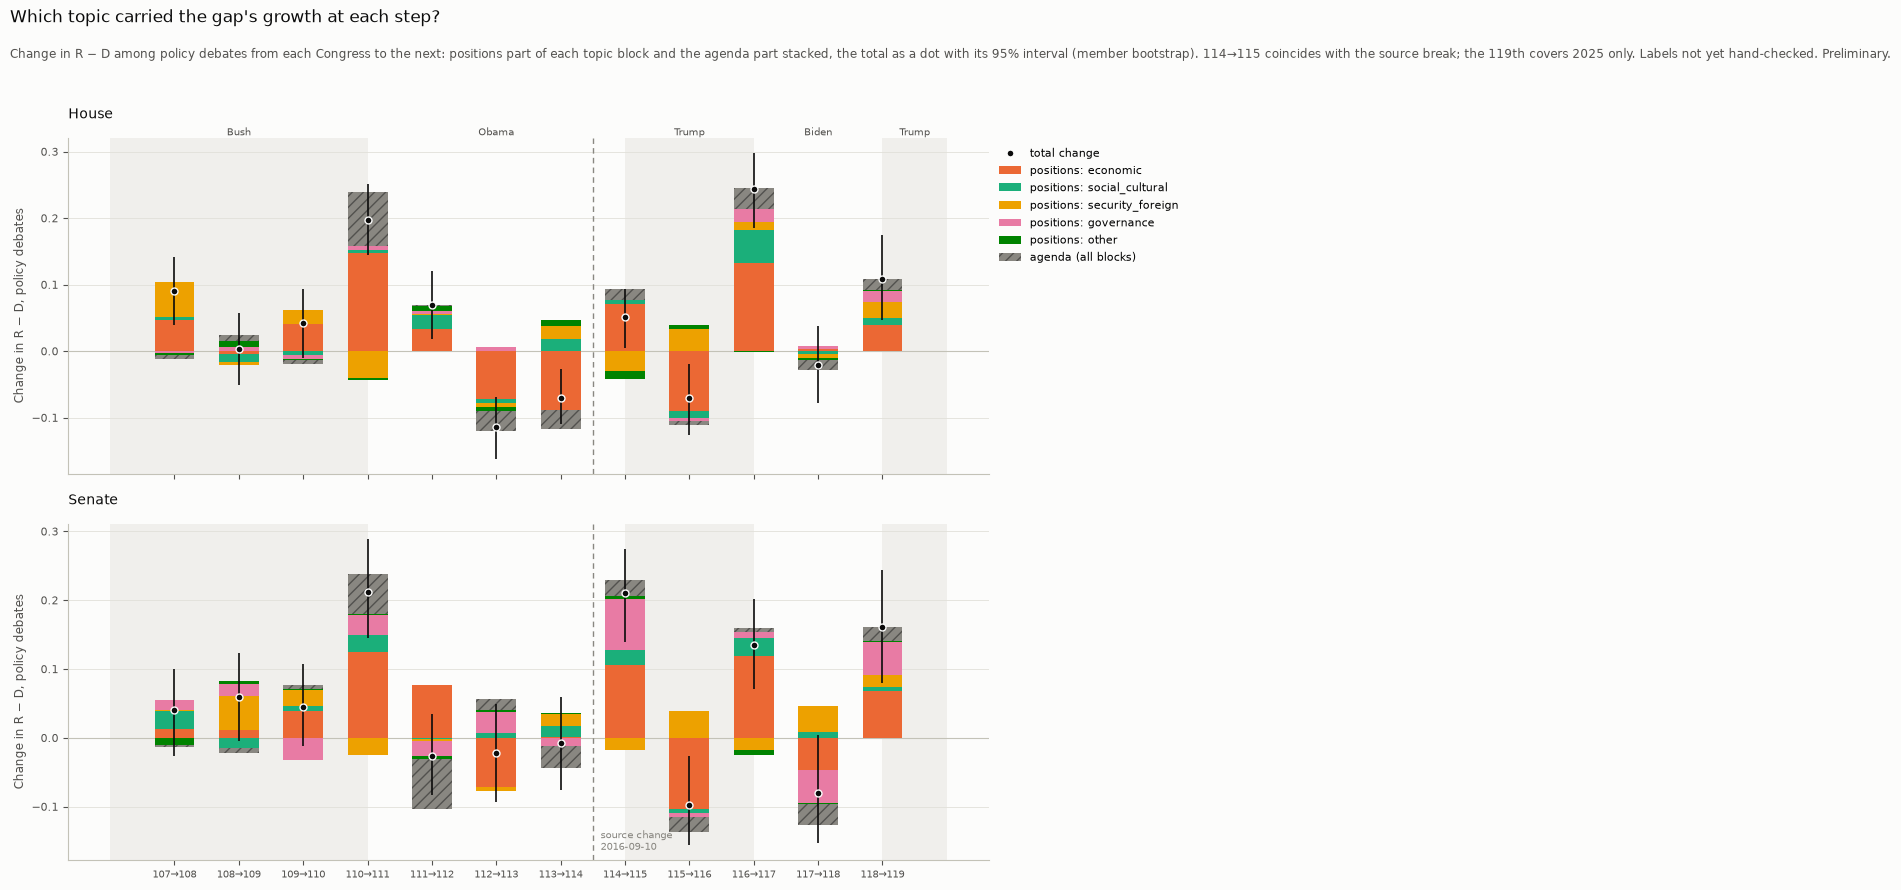

In [5]:
STEPS = consecutive_steps(CONGRESSES)
PERIODS = step_periods(STEPS)
print("Periods:", pd.Series(PERIODS).to_dict())
steps_point, steps_draws = timed(
    "step decomposition bootstrap", bootstrap_step_decomposition, policy, STEPS, n_draws=DEEP_DIVE_BOOTSTRAP
)

# Check 1: the steps add up to the change from the first to the last Congress.
whole = gap_decomposition(policy, {"whole": ((FIRST_CONGRESS,), (LAST_CONGRESS,))})
for chamber in ("H", "S"):
    summed = steps_point.query("component == 'total' and chamber == @chamber")["value"].sum()
    target = whole.query("component == 'total' and chamber == @chamber")["value"].iloc[0]
    assert abs(summed - target) < 1e-12, chamber
# Check 2: the switch steps reproduce notebook 09, intervals included.
CHANGES = list(white_house_changes(CONGRESSES))
committed = pd.read_csv(METRICS_DIR / f"deepdive_switch_decomposition_{RUN}.csv")
committed = committed[committed["comparison"].isin(CHANGES)]
key = ["comparison", "chamber", "component", "topic_block"]
check = committed.merge(steps_point, on=key, suffixes=("_09", ""), validate="one_to_one")
assert len(check) == len(committed)
for column in ("value", "ci_low", "ci_high"):
    assert np.allclose(check[column], check[f"{column}_09"], rtol=0, atol=1e-12), column
print(f"Steps add up to {FIRST_CONGRESS}→{LAST_CONGRESS}; switch steps {CHANGES} reproduce notebook 09.")

steps_point["period"] = steps_point["comparison"].map(PERIODS)
steps_point["congress_from"] = steps_point["comparison"].str.split("→").str[0].astype(int)
by_period = period_sums(steps_point, steps_draws, PERIODS)
fig = plot_steps_decomposition(
    steps_point,
    "Which topic carried the gap's growth at each step?",
    subtitle=("Change in R − D among policy debates from each Congress to the next: positions part of each topic "
              "block and the agenda part stacked, the total as a dot with its 95% interval (member bootstrap). "
              f"114→115 coincides with the source break; the {LAST_CONGRESS}th covers 2025 only. {SUB}"),
)
keep(fig, "deepdive_steps_decomposition")
tables |= {"steps_decomposition": steps_point, "steps_by_period": by_period}

In [6]:
order = list(dict.fromkeys(PERIODS.values()))
sums = by_period[by_period["kind"] == "sum"]
print("Total change per period, and its share of the whole growth:")
totals = sums[sums["component"] == "total"]
display(totals.assign(value_ci=with_ci(totals, "value", 3), share=(100 * totals["share_of_growth"]).round(0))
        .pivot(index="period", columns="chamber", values=["value_ci", "share", "n_steps"]).reindex(order))
for component, label in (("contribution", "Contribution of each block to the change in the gap (weighted by its share)"),
                         ("within", "Change of R − D within each block (unweighted)")):
    print(label + ":")
    part = sums[sums["component"] == component]
    display(part.assign(value_ci=with_ci(part, "value", 3))
            .pivot(index=["period"], columns=["chamber", "topic_block"], values="value_ci").reindex(order))
print("Joint test that the four policy blocks are equal (bootstrap covariance, df = 3):")
by_period[by_period["kind"] == "joint"].pivot(index="period", columns=["chamber", "component"], values="p").reindex(order)

Total change per period, and its share of the whole growth:


value_ci                          share       n_steps     
chamber                                H                        S     H     S       H    S
period                                                                                    
Bush 2001-2008   +0.137 [+0.071, +0.197]  +0.145 [+0.077, +0.217]  26.0  23.0     3.0  3.0
switch 110→111   +0.196 [+0.145, +0.252]  +0.212 [+0.144, +0.289]  37.0  34.0     1.0  1.0
Obama 2009-2016  -0.115 [-0.171, -0.059]  -0.057 [-0.149, +0.023] -22.0  -9.0     3.0  3.0
switch 114→115   +0.051 [+0.004, +0.094]  +0.210 [+0.140, +0.274]  10.0  33.0     1.0  1.0
Trump 2017-2020  -0.071 [-0.127, -0.019]  -0.097 [-0.155, -0.027] -13.0 -15.0     1.0  1.0
switch 116→117   +0.244 [+0.185, +0.298]  +0.135 [+0.071, +0.201]  46.0  21.0     1.0  1.0
Biden 2021-2024  -0.021 [-0.079, +0.038]  -0.080 [-0.153, +0.004]  -4.0 -13.0     1.0  1.0
switch 118→119   +0.109 [+0.046, +0.174]  +0.161 [+0.079, +0.243]  21.0  26.0     1.0  1.0

Contribution of each block to the change in the gap (weighted by its share):


chamber                                H                                                                                                                            S                           \
topic_block                     economic               governance                    other         security_foreign          social_cultural                 economic               governance   
period                                                                                                                                                                                           
Bush 2001-2008   +0.085 [+0.041, +0.127]  -0.006 [-0.014, +0.003]  +0.006 [-0.009, +0.020]  +0.063 [+0.034, +0.090]  -0.010 [-0.030, +0.009]  +0.061 [+0.016, +0.103]  +0.004 [-0.014, +0.022]   
switch 110→111   +0.176 [+0.141, +0.213]  +0.011 [+0.001, +0.021]  +0.017 [+0.006, +0.028]  -0.011 [-0.034, +0.010]  +0.004 [-0.010, +0.020]  +0.151 [+0.105, +0.197]  +0.025 [+0.006, +0.043]   
Obama 2009-2016  -0.156 [-0.194, -0.116]  +0.010 [-0.001, +0.021]  -0.015 [-0.027, -0.002]  -0.004 [-0.026, +0.019]  +0.050 [+0.036, +0.066]  -0.048 [-0.102, +0.005]  -0.010 [-0.025, +0.005]   
switch 114→115   +0.075 [+0.043, +0.106]  -0.004 [-0.013, +0.006]  -0.002 [-0.014, +0.008]  -0.023 [-0.044, -0.003]  +0.005 [-0.010, +0.020]  +0.118 [+0.079, +0.153]  +0.055 [+0.039, +0.073]   
Trump 2017-2020  -0.098 [-0.133, -0.066]  -0.011 [-0.028, +0.007]  +0.004 [-0.009, +0.015]  +0.033 [+0.013, +0.054]  +0.000 [-0.018, +0.019]  -0.111 [-0.150, -0.065]  -0.006 [-0.024, +0.014]   
switch 116→117   +0.131 [+0.099, +0.165]  +0.022 [+0.005, +0.040]  +0.015 [+0.004, +0.027]  +0.008 [-0.016, +0.030]  +0.068 [+0.048, +0.084]  +0.112 [+0.076, +0.151]  +0.007 [-0.017, +0.032]   
Biden 2021-2024  +0.004 [-0.027, +0.034]  +0.009 [-0.005, +0.022]  -0.014 [-0.027, -0.001]  -0.016 [-0.045, +0.012]  -0.004 [-0.025, +0.018]  -0.064 [-0.099, -0.030]  -0.040 [-0.065, -0.012]   
switch 118→119   +0.050 [+0.012, +0.083]  +0.019 [+0.007, +0.033]  +0.009 [-0.005, +0.024]  +0.042 [+0.014, +0.073]  -0.012 [-0.031, +0.007]  +0.101 [+0.065, +0.145]  +0.042 [+0.008, +0.084]   

chamber                                                                                     
topic_block                        other         security_foreign          social_cultural  
period                                                                                      
Bush 2001-2008   -0.003 [-0.017, +0.009]  +0.064 [+0.038, +0.091]  +0.020 [-0.006, +0.054]  
switch 110→111   +0.021 [+0.011, +0.034]  -0.006 [-0.034, +0.023]  +0.021 [+0.001, +0.049]  
Obama 2009-2016  -0.022 [-0.038, -0.007]  -0.016 [-0.048, +0.013]  +0.039 [+0.017, +0.062]  
switch 114→115   +0.020 [+0.004, +0.036]  +0.009 [-0.019, +0.041]  +0.009 [-0.009, +0.027]  
Trump 2017-2020  -0.009 [-0.022, +0.005]  +0.025 [-0.001, +0.048]  +0.003 [-0.022, +0.024]  
switch 116→117   +0.009 [-0.007, +0.026]  -0.023 [-0.047, -0.000]  +0.030 [+0.006, +0.057]  
Biden 2021-2024  -0.011 [-0.030, +0.004]  +0.008 [-0.029, +0.051]  +0.028 [+0.006, +0.055]  
switch 118→119   +0.016 [-0.001, +0.034]  +0.043 [+0.005, +0.082]  -0.040 [-0.060, -0.020]

Change of R − D within each block (unweighted):


chamber                                H                                                                                                                            S                           \
topic_block                     economic               governance                    other         security_foreign          social_cultural                 economic               governance   
period                                                                                                                                                                                           
Bush 2001-2008   +0.191 [+0.101, +0.278]  +0.004 [-0.140, +0.133]  +0.028 [-0.101, +0.142]  +0.245 [+0.148, +0.345]  -0.095 [-0.292, +0.093]  +0.140 [+0.041, +0.237]  -0.055 [-0.169, +0.076]   
switch 110→111   +0.252 [+0.194, +0.316]  +0.089 [-0.051, +0.228]  -0.041 [-0.150, +0.076]  -0.184 [-0.285, -0.078]  +0.053 [-0.137, +0.237]  +0.208 [+0.129, +0.292]  +0.283 [+0.169, +0.384]   
Obama 2009-2016  -0.244 [-0.305, -0.175]  +0.223 [+0.061, +0.378]  +0.147 [+0.040, +0.260]  +0.058 [-0.065, +0.181]  +0.364 [+0.231, +0.502]  -0.022 [-0.131, +0.078]  -0.068 [-0.230, +0.064]   
switch 114→115   +0.144 [+0.078, +0.209]  -0.008 [-0.150, +0.137]  -0.126 [-0.221, -0.018]  -0.133 [-0.228, -0.049]  +0.005 [-0.104, +0.121]  +0.241 [+0.155, +0.321]  +0.412 [+0.307, +0.543]   
Trump 2017-2020  -0.197 [-0.263, -0.127]  -0.046 [-0.191, +0.097]  +0.085 [-0.032, +0.189]  +0.191 [+0.088, +0.291]  -0.061 [-0.182, +0.055]  -0.249 [-0.345, -0.140]  -0.024 [-0.107, +0.063]   
switch 116→117   +0.318 [+0.242, +0.396]  +0.148 [+0.028, +0.260]  -0.021 [-0.126, +0.096]  +0.065 [-0.043, +0.167]  +0.256 [+0.175, +0.337]  +0.307 [+0.214, +0.400]  +0.071 [-0.037, +0.185]   
Biden 2021-2024  +0.007 [-0.068, +0.080]  +0.044 [-0.084, +0.155]  -0.043 [-0.152, +0.077]  -0.032 [-0.136, +0.069]  -0.019 [-0.103, +0.056]  -0.147 [-0.269, -0.039]  -0.211 [-0.314, -0.110]   
switch 118→119   +0.084 [+0.000, +0.152]  +0.187 [+0.060, +0.322]  +0.029 [-0.115, +0.155]  +0.126 [+0.011, +0.232]  +0.056 [-0.037, +0.149]  +0.179 [+0.069, +0.304]  +0.197 [+0.048, +0.314]   

chamber                                                                                     
topic_block                        other         security_foreign          social_cultural  
period                                                                                      
Bush 2001-2008   -0.049 [-0.184, +0.093]  +0.297 [+0.191, +0.405]  +0.164 [-0.086, +0.364]  
switch 110→111   +0.033 [-0.092, +0.156]  -0.135 [-0.273, +0.006]  +0.329 [+0.094, +0.624]  
Obama 2009-2016  +0.063 [-0.097, +0.222]  +0.010 [-0.141, +0.147]  +0.111 [-0.097, +0.326]  
switch 114→115   +0.059 [-0.092, +0.204]  -0.035 [-0.138, +0.090]  +0.154 [+0.002, +0.319]  
Trump 2017-2020  +0.033 [-0.126, +0.193]  +0.228 [+0.132, +0.335]  -0.047 [-0.257, +0.162]  
switch 116→117   -0.121 [-0.275, +0.045]  -0.120 [-0.228, -0.028]  +0.193 [-0.001, +0.369]  
Biden 2021-2024  -0.039 [-0.188, +0.121]  +0.136 [+0.001, +0.297]  +0.041 [-0.056, +0.167]  
switch 118→119   +0.042 [-0.132, +0.230]  +0.088 [-0.048, +0.224]  +0.030 [-0.103, +0.127]

Joint test that the four policy blocks are equal (bootstrap covariance, df = 3):


chamber                    H                       S           
component       contribution     within contribution     within
period                                                         
Bush 2001-2008     6.143e-08  7.572e-04    1.334e-03  3.270e-04
switch 110→111     1.643e-21  4.936e-13    5.409e-09  2.121e-06
Obama 2009-2016    6.624e-25  1.248e-19    1.987e-03  5.680e-01
switch 114→115     6.521e-06  7.223e-06    2.244e-07  7.701e-08
Trump 2017-2020    4.837e-12  1.747e-08    2.204e-07  1.091e-08
switch 116→117     3.813e-11  3.819e-04    1.560e-08  1.726e-08
Biden 2021-2024    3.958e-01  7.567e-01    8.977e-07  3.035e-04
switch 118→119     6.487e-04  3.576e-01    3.285e-12  1.478e-01

**Reading it (2).** Preliminary. Two questions, kept apart: *which topic carried the
growth* (contribution, weighted by the block's share of debates) and *which topic
polarized most* (change within the block, unweighted).

- **When.** The gap grew at the changes of the White House and partly receded within
  presidencies. The four switch steps add +0.60 in the House and +0.72 in the Senate,
  more than the whole growth from the 107th to the 119th (+0.53 and +0.63): 110→111
  +0.20 [+0.15, +0.25] / +0.21 [+0.14, +0.29]; 114→115 +0.05 [+0.00, +0.09] / +0.21
  [+0.14, +0.27]; 116→117 +0.24 [+0.19, +0.30] / +0.14 [+0.07, +0.20]; 118→119 +0.11
  [+0.05, +0.17] / +0.16 [+0.08, +0.24]. Within presidencies the gap rose under Bush (+0.14 /
  +0.15) and fell under Obama in the House (−0.12 [−0.17, −0.06]) and under Trump's first
  term (−0.07 / −0.10); Biden and the Senate under Obama are not clear.
- **Which topic carried it: economic.** It carried most of the growth at the switch steps
  (House 110→111 +0.18 of +0.20, 116→117 +0.13 of +0.24; Senate 110→111 +0.15, 114→115
  +0.12, 118→119 +0.10) and most of the falls within presidencies (House under Obama
  −0.16). The economic block is about half of all policy debates, so it weighs most.
  Social-cultural added at 116→117 in the House (+0.07 [+0.05, +0.08]); governance at
  114→115 in the Senate (+0.06 [+0.04, +0.07]).
- **Which topic polarized most depends on the period.** Within the blocks, unweighted:
  under Obama the House gap fell in economics (−0.24) but widened in social-cultural (+0.36
  [+0.23, +0.50]) and governance (+0.22); at 114→115 the Senate's governance gap widened by
  +0.41 [+0.31, +0.54]; security-foreign widened under Bush (+0.25 House, +0.30 Senate) and
  narrowed at 110→111 in the House (−0.18). A small block can polarize strongly and still add little to the
  overall gap.
- The four blocks differ in almost every period (joint p < 0.01), not under Biden in the
  House (p = 0.40) nor within blocks in the Senate under Obama (p = 0.57).
- 114→115 coincides with the source break; the 119th covers 2025 only.

# Part II — Designs

## 3. A majority lost in one chamber only (difference-in-differences)

**Question.** When a party loses the majority in one chamber while keeping (or not having)
the White House, do its members in that chamber change how they speak — beyond the change
of the same party's members in the other chamber, under the same president at the same
time?

**How.** Cases are read from the majority constants (`chamber_flip_cases`): steps t → t+1
in which exactly one chamber changes hands and the president's party stays. Treated: the
members of the party that loses the flipping chamber, in that chamber; control: the same
party's members in the other chamber. Speech-level model per case: member fixed effects +
post + post × treated (`post_treated` is the difference-in-differences), for extremity and
tone, clustered by member; pooled over the main cases as a stacked design with member × case
and case × post fixed effects. Mirror: the party that gains the chamber against itself in the
other chamber. Placebo: the same groups one step earlier (t−1 → t), where t−1 is in the
data. Main variant: only members who sit in the same chamber in both Congresses (Voteview
service); robustness: all members; the 107th → 108th case (its Senate changed hands three
times within the 107th) only in a robustness pool.

**Source break (decided 2026-11-03).** 9% of the 114th Congress's speeches come from govinfo
(after 2016-09-10). In the main variant the 113→114 case uses only the 114th's Stanford
speeches, so every main case lies within one source; robustness: all of them.

**O8 (decided 2026-11-03).** This is the one model in which both chambers enter together. O8
forbids pooling chambers because the source break changes what is recorded *differently* in
each chamber, so their levels and trends across the break cannot be compared. Here member
fixed effects remove every level, case × post removes the shared change, and what remains is
the difference between two *changes within one source*. That needs only that, within a
source, recording does not change differently by chamber from one Congress to the next. The
two chambers' own changes are shown beside every estimate.

**Placebos are not all clean.** 114→115 (placebo for 115→116) crosses the source break;
in 116→117 (placebo for 117→118) the control group itself — Senate Democrats — gained the
majority; in 110→111 (placebo for 111→112) the White House changed for both groups alike.
Only the placebos of 113→114 and 111→112 are read.

,case,before,after,chamber,loses,gains,president_party,status,note
0,107→108,107,108,S,D,R,R,robustness,
1,111→112,111,112,H,D,R,D,main,
2,113→114,113,114,S,D,R,D,main,
3,115→116,115,116,H,R,D,R,main,
4,117→118,117,118,H,D,R,D,main,control chamber (Senate) changed hands within the 117th


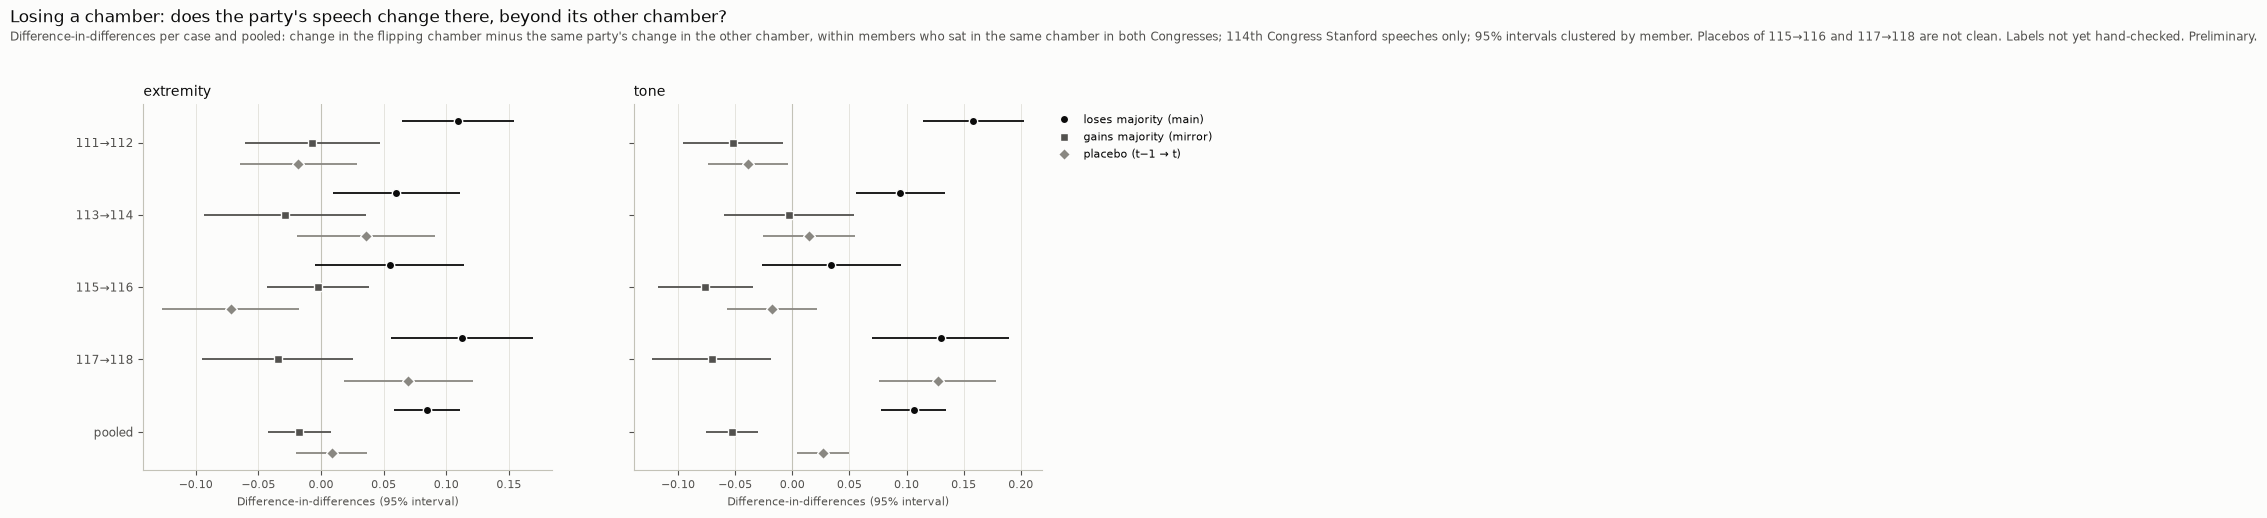

In [7]:
cases = chamber_flip_cases(CONGRESSES)
display(cases)
EXPECTED_CASES = {"107→108": "robustness", "111→112": "main", "113→114": "main", "115→116": "main", "117→118": "main"}
assert dict(zip(cases["case"], cases["status"])) == EXPECTED_CASES, "cases differ from the brief: stop and ask"
membership = chamber_membership()
served = set(zip(membership["icpsr"].astype(int), membership["congress_number"], membership["chamber"]))
main_cases = cases[cases["status"] == "main"]
PLACEBO_STATUS = {"111→112": "read (White House changed for both)", "113→114": "read (clean)",
                  "115→116": "not clean: crosses the source break",
                  "117→118": "not clean: control gained the Senate majority"}
variants = {
    "loses majority (main)": {"cases": main_cases},
    "gains majority (mirror)": {"cases": main_cases, "role": "gains"},
    "loses, all members": {"cases": main_cases, "same_chamber": False},
    "loses, 114th all sources": {"cases": main_cases, "stanford_only": ()},
    "loses, with 107→108": {"cases": cases},
    "placebo (t−1 → t)": {"cases": main_cases, "placebo": True},
}
flip = []
for name, kwargs in variants.items():
    data = chamber_flip_data(df, served=served, **kwargs)
    for value in VALUES:
        flip.append(chamber_flip_did(data, value).assign(variant=name))
flip_did = pd.concat(flip, ignore_index=True)
flip_did["placebo_status"] = np.where(flip_did["variant"].str.startswith("placebo"),
                                      flip_did["case"].map(PLACEBO_STATUS), "")
shown = flip_did[flip_did["kind"].isin(["case", "pooled"])
                 & flip_did["variant"].isin(["loses majority (main)", "gains majority (mirror)", "placebo (t−1 → t)"])]
fig = plot_did_cases(
    shown, ["loses majority (main)", "gains majority (mirror)", "placebo (t−1 → t)"],
    "Losing a chamber: does the party's speech change there, beyond its other chamber?",
    subtitle=("Difference-in-differences per case and pooled: change in the flipping chamber minus the same party's change "
              "in the other chamber, within members who sat in the same chamber in both Congresses; 114th Congress Stanford "
              f"speeches only; 95% intervals clustered by member. Placebos of 115→116 and 117→118 are not clean. {SUB}"),
)
keep(fig, "deepdive_chamber_flip_did")
tables |= {"chamber_flip_cases": cases, "chamber_flip_did": flip_did}

In [8]:
est = flip_did[flip_did["kind"].isin(["case", "pooled"])]
display(est.assign(coef_ci=with_ci(est, "coef", 3)).pivot_table(
    index=["variant", "case"], columns="value", values=["coef_ci", "n_members"], aggfunc="first"))
own = flip_did[(flip_did["kind"] == "own change") & (flip_did["variant"] == "loses majority (main)")]
print("Own change of each chamber, t → t+1, within members (main variant):")
own.assign(coef_ci=with_ci(own, "coef", 3)).pivot_table(index=["case", "chamber"], columns="value",
                                                         values=["coef_ci", "n_members"], aggfunc="first")

coef_ci                          n_members     
value                                           extremity                     tone extremity tone
variant                  case                                                                    
gains majority (mirror)  111→112  -0.007 [-0.061, +0.047]  -0.052 [-0.095, -0.008]       191  191
                         113→114  -0.029 [-0.094, +0.036]  -0.003 [-0.059, +0.054]       243  243
                         115→116  -0.002 [-0.044, +0.039]  -0.076 [-0.118, -0.034]       217  217
                         117→118  -0.035 [-0.095, +0.025]  -0.071 [-0.123, -0.019]       220  220
                         pooled   -0.017 [-0.043, +0.008]  -0.052 [-0.075, -0.030]       653  653
loses majority (main)    111→112  +0.109 [+0.064, +0.154]  +0.158 [+0.114, +0.203]       232  232
                         113→114  +0.060 [+0.010, +0.111]  +0.094 [+0.055, +0.134]       217  217
                         115→116  +0.055 [-0.004, +0.114]  +0.034 [-0.027, +0.095]       210  210
                         117→118  +0.113 [+0.056, +0.170]  +0.130 [+0.070, +0.190]       222  222
                         pooled   +0.085 [+0.058, +0.111]  +0.106 [+0.078, +0.134]       595  595
loses, 114th all sources 111→112  +0.109 [+0.064, +0.154]  +0.158 [+0.114, +0.203]       232  232
                         113→114  +0.066 [+0.015, +0.116]  +0.104 [+0.066, +0.142]       219  219
                         115→116  +0.055 [-0.004, +0.114]  +0.034 [-0.027, +0.095]       210  210
                         117→118  +0.113 [+0.056, +0.170]  +0.130 [+0.070, +0.190]       222  222
                         pooled   +0.086 [+0.059, +0.113]  +0.109 [+0.081, +0.136]       596  596
loses, all members       111→112  +0.109 [+0.064, +0.154]  +0.158 [+0.114, +0.203]       321  321
                         113→114  +0.061 [+0.010, +0.111]  +0.094 [+0.055, +0.133]       270  270
                         115→116  +0.050 [-0.009, +0.108]  +0.026 [-0.034, +0.086]       322  322
                         117→118  +0.113 [+0.056, +0.170]  +0.130 [+0.070, +0.190]       292  292
                         pooled   +0.084 [+0.057, +0.110]  +0.104 [+0.076, +0.132]       845  845
loses, with 107→108      107→108  -0.006 [-0.053, +0.040]  -0.007 [-0.041, +0.026]       227  227
                         111→112  +0.109 [+0.064, +0.154]  +0.158 [+0.114, +0.203]       232  232
                         113→114  +0.060 [+0.010, +0.111]  +0.094 [+0.055, +0.134]       217  217
                         115→116  +0.055 [-0.004, +0.114]  +0.034 [-0.027, +0.095]       210  210
                         117→118  +0.113 [+0.056, +0.170]  +0.130 [+0.070, +0.190]       222  222
                         pooled   +0.063 [+0.042, +0.085]  +0.080 [+0.057, +0.102]       680  680
placebo (t−1 → t)        111→112  -0.018 [-0.065, +0.029]  -0.039 [-0.074, -0.004]       273  273
                         113→114  +0.036 [-0.019, +0.091]  +0.014 [-0.026, +0.055]       199  199
                         115→116  -0.072 [-0.127, -0.017]  -0.018 [-0.058, +0.021]       258  258
                         117→118  +0.070 [+0.018, +0.122]  +0.127 [+0.076, +0.178]       246  246
                         pooled   +0.008 [-0.020, +0.037]  +0.027 [+0.004, +0.049]       694  694

Own change of each chamber, t → t+1, within members (main variant):


coef_ci                          n_members     
value                          extremity                     tone extremity tone
case    chamber                                                                 
111→112 H        +0.038 [+0.009, +0.067]  +0.165 [+0.134, +0.196]       180  180
        S        -0.071 [-0.106, -0.037]  +0.007 [-0.025, +0.039]        52   52
113→114 H        -0.021 [-0.050, +0.008]  -0.036 [-0.063, -0.008]       172  172
        S        +0.039 [-0.002, +0.081]  +0.059 [+0.031, +0.087]        45   45
115→116 H        -0.038 [-0.080, +0.004]  +0.095 [+0.058, +0.132]       164  164
        S        -0.093 [-0.135, -0.051]  +0.061 [+0.012, +0.110]        46   46
117→118 H        -0.002 [-0.042, +0.039]  +0.129 [+0.094, +0.164]       174  174
        S        -0.114 [-0.155, -0.074]  -0.001 [-0.050, +0.048]        48   48

**Reading it (3).** Preliminary; the design compares changes, it does not show why they
happen.

- **Members of a party that lost a chamber changed more than their colleagues in the
  other chamber.** Pooled over the four main cases, relative to the same party in the
  other chamber, they spoke further out by +0.085 [+0.058, +0.111] and harsher by +0.106
  [+0.078, +0.134]. Per case: 111→112 (House Democrats) +0.11 / +0.16; 113→114 (Senate
  Democrats) +0.06 / +0.09; 117→118 (House Democrats) +0.11 / +0.13; 115→116 (House
  Republicans) smaller and not clear (+0.06 [−0.00, +0.11] / +0.03 [−0.03, +0.10]).
- **The party gaining the chamber** shows no clear change in extremity (−0.017
  [−0.043, +0.008]) and a slightly milder tone (−0.052 [−0.075, −0.030]).
- **Robust** to all members instead of those staying in their chamber (+0.084 / +0.104)
  and to all of the 114th's speeches (+0.086 / +0.109). With the impure 107→108 case,
  which shows nothing itself (−0.01 / −0.01), the pooled effect is +0.063 / +0.080.
- **Placebos.** The two that can be read are near zero: 113→114 a Congress earlier +0.04
  [−0.02, +0.09] / +0.01 [−0.03, +0.06]; 111→112 −0.02 [−0.07, +0.03] / −0.04
  [−0.07, −0.00] (small, opposite sign). The two not clean ones are not zero (117→118:
  +0.07 / +0.13), as expected where the control itself changed status.
- **Read with the own changes.** A difference-in-differences is relative: in 111→112 the
  tone effect comes from House Democrats (+0.17) while Senate Democrats stayed (+0.01); in
  117→118 the extremity effect comes mostly from Senate Democrats moving toward the centre
  (−0.11) while House Democrats stayed (−0.00).
- Both chambers enter one model here; this compares changes within one source (O8, see
  above).

## 4. Event study around the changes of the White House

**Question.** When the White House changes hands, does the party that loses it change its
speech more than the party that wins it — and was it already moving before?

**How.** The changes are read from the presidents (`white_house_changes`). k = Congress −
the new president's first Congress, from k = −2 to +1 where the data reach (the last change
has no k = +1); reference k = −1. Treated: the party that loses the White House; control:
the party that wins it. Stacked over the changes, per chamber: member × change fixed effects,
change × k fixed effects, effects treated × k, and `chamber_minority` as a control (as model
C), clustered by member. The k = −2 effect is the pre-trend test. Beside it, each side's own
path within members, relative to k = −1 (descriptive).

**Source break.** At the 114→115 change the break falls between k = −1 (the 114th, mostly
Stanford) and k = 0. The comparison between the two parties removes a source effect common
to both; a source effect that differs by party would not be removed.

Speeches per change and k (both chambers):


k,-2,-1,0,1
switch,,,,
110→111,5505.0,5463.0,5648.0,5607.0
114→115,5603.0,5454.0,5569.0,5430.0
116→117,5569.0,5430.0,5409.0,5194.0
118→119,5409.0,5194.0,5208.0,NaN


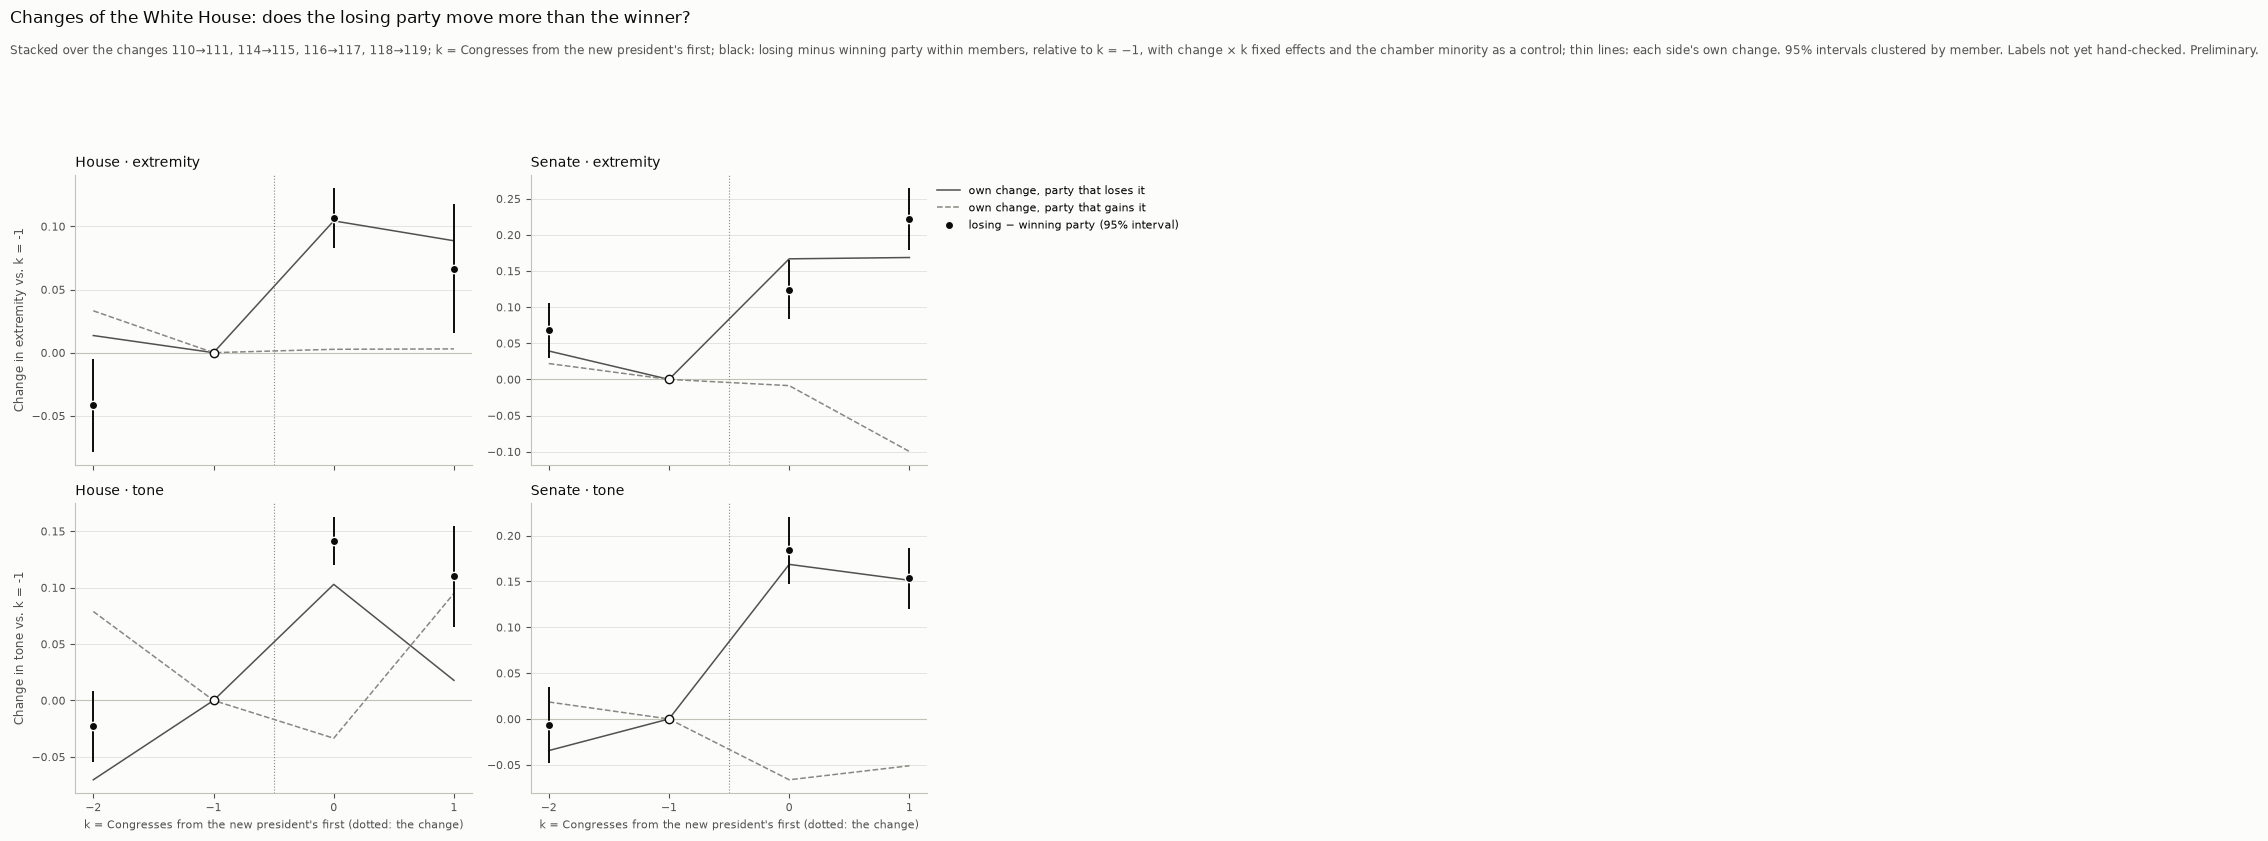

coef_ci                                  p       
value                       extremity                     tone extremity   tone
chamber k                                                                      
H       -2.0  -0.041 [-0.078, -0.005]  -0.023 [-0.054, +0.009]     0.027  0.156
         0.0  +0.106 [+0.083, +0.130]  +0.142 [+0.120, +0.163]       0.0    0.0
         1.0  +0.066 [+0.015, +0.117]  +0.110 [+0.065, +0.155]     0.011    0.0
S       -2.0  +0.068 [+0.029, +0.106]  -0.007 [-0.048, +0.035]     0.001  0.747
         0.0  +0.124 [+0.083, +0.165]  +0.184 [+0.147, +0.221]       0.0    0.0
         1.0  +0.222 [+0.180, +0.264]  +0.153 [+0.120, +0.187]       0.0    0.0

Pre-trend (k = −2):


,chamber,value,coef,ci_low,ci_high,p,n_members
0,H,extremity,-0.041,-0.078,-0.005,2.721e-02,1178
4,S,extremity,0.068,0.029,0.106,5.458e-04,234
8,H,tone,-0.023,-0.054,0.009,1.564e-01,1178
12,S,tone,-0.007,-0.048,0.035,7.467e-01,234


In [9]:
es_data = wh_event_study_data(df)
print("Speeches per change and k (both chambers):")
display(es_data.groupby(["switch", "k"]).size().unstack())
es_effects = pd.concat([wh_event_study(es_data, value) for value in VALUES], ignore_index=True)
es_paths = pd.concat([party_own_paths(es_data, value) for value in VALUES], ignore_index=True)
fig = plot_event_study(
    es_effects, es_paths,
    "Changes of the White House: does the losing party move more than the winner?",
    subtitle=("Stacked over the changes 110→111, 114→115, 116→117, 118→119; k = Congresses from the new president's first; "
              "black: losing minus winning party within members, relative to k = −1, with change × k fixed effects and the "
              f"chamber minority as a control; thin lines: each side's own change. 95% intervals clustered by member. {SUB}"),
)
keep(fig, "deepdive_wh_event_study")
tables["wh_event_study"] = pd.concat([es_effects.assign(kind="effect"), es_paths.assign(kind="own path")],
                                     ignore_index=True)
shown = es_effects[es_effects["term"].str.startswith("treated")]
display(shown.assign(coef_ci=with_ci(shown, "coef", 3)).pivot(index=["chamber", "k"], columns="value",
                                                               values=["coef_ci", "p"]))
print("Pre-trend (k = −2):")
shown[shown["k"] == -2][["chamber", "value", "coef", "ci_low", "ci_high", "p", "n_members"]]

**Reading it (4).** Preliminary.

- **After a change of the White House the losing party speaks further out and harsher than
  the winning one.** Relative to the Congress before (k = −1), at k = 0: House extremity
  +0.106 [+0.083, +0.130], tone +0.142 [+0.120, +0.163]; Senate +0.124 [+0.083, +0.165] and
  +0.184 [+0.147, +0.221]. At k = +1 the difference persists (House +0.07 / +0.11, Senate
  +0.22 / +0.15).
- **Pre-trend:** for **tone** none (House −0.02 [−0.05, +0.01], Senate −0.01
  [−0.05, +0.03]). For **extremity** the test fails in both chambers, with opposite signs
  (House −0.041 [−0.078, −0.005], Senate +0.068 [+0.029, +0.106]); the jump at k = 0 is
  larger than either, but the extremity estimates are less clean than the tone ones.
- **Own paths:** the losing side moves out at k = 0 (House +0.10, Senate +0.17) and stays
  there; the winning side barely moves in extremity at k = 0 (House +0.00, Senate −0.01)
  and turns milder in tone (−0.03 / −0.07). So the difference comes mainly from the party
  that lost.
- At 114→115 the source break lies between k = −1 and k = 0; comparing the parties removes
  a source effect common to both, not one that differs by party.

## 4b. The power ladder: how hard, depending on how much power the own party has?

**Question.** Model C of notebook 08 adds two losses of power, each on its own: the White House
(`opposition`) and the majority in the own chamber (`chamber_minority`). Is losing both more
than the sum of losing each — does a party left with nothing speak harsher, or further out,
than its two single losses predict?

**How.** Each speech gets its party's power from the constants: the president per Congress
(`PRESIDENTS_BY_CONGRESS`) and the majority of the speaker's own chamber (`HOUSE_MAJORITY`,
`SENATE_MAJORITY`; the 107th and 117th Senate by the speech's date, as `add_chamber_control`).
Four levels: **full power** (White House and own-chamber majority; the reference),
**White House only**, **chamber only**, **nothing**. Per party × chamber: member fixed effects,
a linear trend in the Congress and one indicator per level (as model C), clustered by member;
tone and extremity apart. The extra test is β(nothing) − β(White House only) − β(chamber only) = 0:
the interaction of the two losses (the same model reparametrized), a Wald test with one degree
of freedom. Cells: speeches, members and member × Congress units per level; a level under 30
speeches or 10 members is marked. **Check:** the model with the two additive indicators
reproduces 08's model C (`deepdive_opposition_models`), by assert.

The president is the one the constant gives the whole Congress, as in notebooks 07 and 08: the
speeches of 3–20 January 2001 and 2021 carry the incoming president (101 substantive speeches,
20 of them in the Senate). Below the model, a background table: per Congress and majority period
the president, the House and Senate majority, and the constellation from the president's view
(unified, one chamber, none).

Speeches (n), members and member × Congress units per power level:


n                                        n_members                                          n_units                                      
power_level   full power White House only chamber only nothing full power White House only chamber only nothing full power White House only chamber only nothing
chamber party                                                                                                                                                   
H       D         2944.0           6229.0       2994.0  7762.0      358.0            352.0        370.0   457.0      428.0            751.0        444.0   944.0
        R         6747.0           2803.0       5803.0  2960.0      574.0            333.0        453.0   333.0     1056.0            369.0        888.0   365.0
S       D         5574.0           1458.0       2076.0  7684.0       98.0             46.0         66.0   110.0      275.0             55.0        103.0   287.0
        R         5727.0           2413.0       1035.0  6912.0      124.0             67.0         56.0    90.0      312.0             99.0         63.0   234.0

Levels under 30 speeches or 10 members: 0


,chamber,party,power_level,n,n_members,n_units,congresses,n_members_varying,small


extremity: the additive model reproduces model C of deepdive_opposition_models_20261018T122536Z.csv
tone: the additive model reproduces model C of deepdive_opposition_models_20261018T122536Z.csv


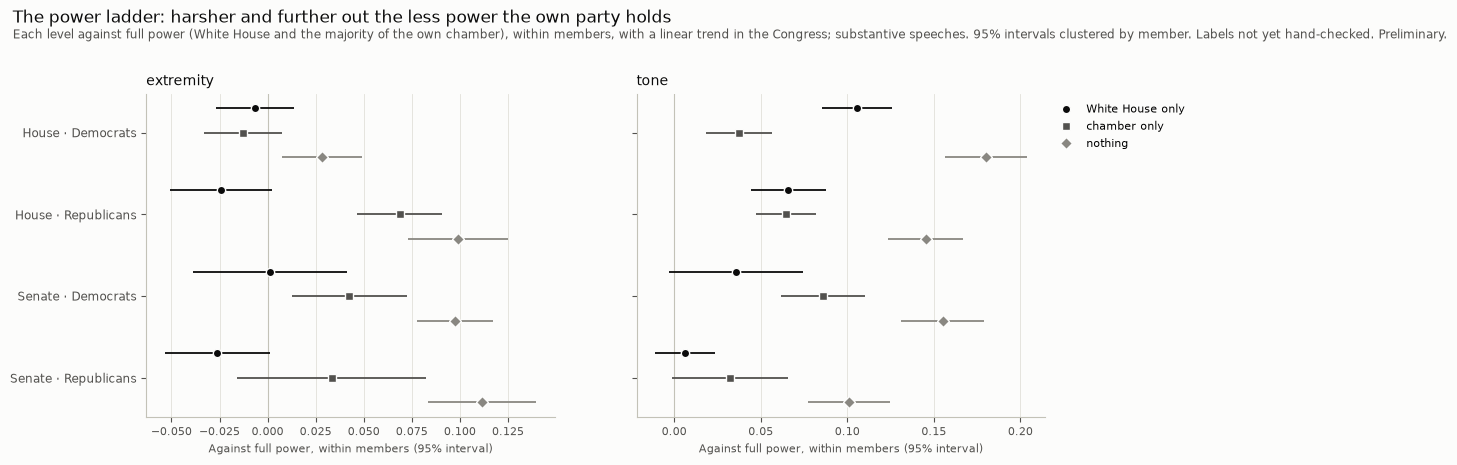

In [10]:
from src.deep_dive import (
    POWER_LEVELS,
    add_power_level,
    check_reproduces,
    power_constellations,
    power_ladder,
    power_ladder_cells,
)
from src.deep_dive_plots import plot_power_ladder

power = add_power_level(df)
ladder_cells = power_ladder_cells(power)
print("Speeches (n), members and member × Congress units per power level:")
display(ladder_cells.pivot_table(index=["chamber", "party"], columns="power_level",
                                 values=["n", "n_members", "n_units"])
        .reindex(columns=list(POWER_LEVELS), level=1))
small = ladder_cells[ladder_cells["small"]]
print(f"Levels under 30 speeches or 10 members: {len(small)}")
display(small)

ladder = pd.concat([power_ladder(power, value) for value in VALUES], ignore_index=True)
committed = pd.read_csv(METRICS_DIR / f"deepdive_opposition_models_{RUN}.csv")
key = ["chamber", "party", "term", "coef", "se"]
for value in VALUES:
    additive = ladder[(ladder["model"] == "additive") & (ladder["value"] == value)]
    model_c = committed[(committed["model"] == "C") & (committed["value"] == value)]
    check_reproduces(additive[key], model_c[key])
    print(f"{value}: the additive model reproduces model C of deepdive_opposition_models_{RUN}.csv")

constellations = power_constellations()
fig = plot_power_ladder(
    ladder,
    "The power ladder: harsher and further out the less power the own party holds",
    subtitle=("Each level against full power (White House and the majority of the own chamber), within members, "
              "with a linear trend in the Congress; substantive speeches. 95% intervals clustered by member. " + SUB),
)
keep(fig, "deepdive_power_ladder")
tables["power_ladder"] = ladder
tables["power_ladder_cells"] = ladder_cells
tables["power_constellations"] = constellations

In [11]:
shown = ladder[ladder["model"] == "ladder"].dropna(subset=["power_level"])
print("Each level against full power, within members (coefficient [95% interval]):")
display(shown.assign(coef_ci=with_ci(shown, "coef", 3))
        .pivot_table(index=["value", "chamber", "party"], columns="power_level", values="coef_ci",
                     aggfunc="first")
        .reindex(columns=list(POWER_LEVELS[1:])))
interaction = ladder[ladder["model"] == "interaction"]
print("Is losing both more than the sum of losing each? β(nothing) − β(White House only) − β(chamber only):")
display(interaction.assign(coef_ci=with_ci(interaction, "coef", 3))
        [["value", "chamber", "party", "coef_ci", "chi2", "p", "n", "n_members"]])
print("Background: the president's constellation per Congress and majority period:")
constellations

Each level against full power, within members (coefficient [95% interval]):


power_level                     White House only             chamber only                  nothing
value     chamber party                                                                           
extremity H       D      -0.007 [-0.027, +0.014]  -0.013 [-0.033, +0.007]  +0.028 [+0.007, +0.049]
                  R      -0.024 [-0.051, +0.002]  +0.069 [+0.047, +0.091]  +0.099 [+0.073, +0.125]
          S       D      +0.001 [-0.039, +0.041]  +0.042 [+0.013, +0.072]  +0.097 [+0.077, +0.117]
                  R      -0.026 [-0.053, +0.001]  +0.033 [-0.016, +0.082]  +0.112 [+0.083, +0.140]
tone      H       D      +0.106 [+0.085, +0.126]  +0.037 [+0.018, +0.056]  +0.180 [+0.157, +0.204]
                  R      +0.066 [+0.045, +0.087]  +0.065 [+0.047, +0.082]  +0.145 [+0.124, +0.167]
          S       D      +0.036 [-0.003, +0.075]  +0.086 [+0.062, +0.110]  +0.155 [+0.131, +0.179]
                  R      +0.006 [-0.011, +0.023]  +0.032 [-0.001, +0.066]  +0.101 [+0.077, +0.125]

Is losing both more than the sum of losing each? β(nothing) − β(White House only) − β(chamber only):


,value,chamber,party,coef_ci,chi2,p,n,n_members
28,extremity,H,D,"+0.048 [+0.022, +0.073]",13.233,2.750e-04,19929,580
29,extremity,H,R,"+0.055 [+0.023, +0.087]",11.433,7.215e-04,18313,695
30,extremity,S,D,"+0.054 [+0.006, +0.102]",4.896,2.692e-02,16792,123
31,extremity,S,R,"+0.104 [+0.042, +0.167]",10.640,1.107e-03,16087,132
60,tone,H,D,"+0.037 [+0.014, +0.060]",9.717,1.825e-03,19929,580
61,tone,H,R,"+0.015 [-0.011, +0.041]",1.229,2.675e-01,18313,695
62,tone,S,D,"+0.033 [-0.014, +0.080]",1.941,1.635e-01,16792,123
63,tone,S,R,"+0.062 [+0.017, +0.107]",7.417,6.462e-03,16087,132


Background: the president's constellation per Congress and majority period:


,congress_number,senate_from,house_majority,senate_majority,president,president_party,constellation,note
0,107,2001-01-03,R,D,Bush,R,one chamber,president as the constant gives the Congress; the outgoing preside...
1,107,2001-01-20,R,R,Bush,R,unified,
2,107,2001-06-06,R,D,Bush,R,one chamber,
3,108,None,R,R,Bush,R,unified,
4,109,None,R,R,Bush,R,unified,
5,110,None,D,D,Bush,R,none,
6,111,None,D,D,Obama,D,unified,
7,112,None,R,D,Obama,D,one chamber,
8,113,None,R,D,Obama,D,one chamber,
9,114,None,R,R,Obama,D,none,


**Reading it (4b).** Preliminary; one model (DeepSeek), labels not hand-checked.
"White House only" means the party has lost its chamber's majority, "chamber only" that it has
lost the White House.

- **With nothing left, a party speaks harshest and furthest out.** Against full power, within
  the same members: tone +0.10 to +0.18 (House D +0.180 [+0.157, +0.204], House R +0.145
  [+0.124, +0.167], Senate D +0.155 [+0.131, +0.179], Senate R +0.101 [+0.077, +0.125]);
  extremity +0.03 to +0.11 (House D +0.028 [+0.007, +0.049], House R +0.099 [+0.073, +0.125],
  Senate D +0.097 [+0.077, +0.117], Senate R +0.112 [+0.083, +0.140]).
- **Losing both is more than the sum of losing each, for extremity in every group:**
  β(nothing) − β(White House only) − β(chamber only) = House D +0.048 [+0.022, +0.073], House R
  +0.055 [+0.023, +0.087], Senate D +0.054 [+0.006, +0.102], Senate R +0.104 [+0.042, +0.167].
  For **tone** only in House D (+0.037 [+0.014, +0.060]) and Senate R (+0.062 [+0.017,
  +0.107]); in House R and Senate D the interval includes 0.
- **The single losses act differently on the two measures.** Losing only the chamber does not
  move extremity anywhere (−0.026 to +0.001, no interval clear of 0) but raises tone in the
  House (D +0.106, R +0.066). Losing only the White House moves House R (+0.069) and Senate D
  (+0.042) further out and raises tone in every group but Senate R (+0.032, interval touching 0).
- **Limits.** The levels are tied to few Congresses and presidents: Senate D "White House only"
  rests on the 114th (plus 9 speeches in January 2021), Senate R "chamber only" on the 114th and
  the first weeks of the 117th. With one linear trend, a level effect can also take up whatever
  else marks those Congresses. Only the 66–89% of members whose level changes identify the
  ladder; no level falls under 30 speeches or 10 members. The additive model reproduces model C
  of notebook 08 exactly, so the ladder refines it rather than replacing it.

## 4c. After elections: how does the losing side react?

**Question.** In the weeks after a general election, does the side that lost speak harsher,
or further out, than the side that won — and has that reaction grown over the years?

**How.**
- **Elections:** every general federal election 2002–2024, presidential years 2004–2024 and
  midterms 2002–2022. The date by rule (the Tuesday after the first Monday in November),
  checked against the brief's list by assert.
- **Windows**, in sitting days per chamber (days with at least one speech of that chamber in
  the corpus, decided at HALT 1): *after* = election day to the end of the Congress (the lame
  duck); *before* = as many sitting days, the last ones before election day. No window crosses
  a Congress boundary. In 2016 the House's before window stops at the source change
  (2016-09-10, decided at HALT 1): 10 sitting days before, 13 after; with the three Stanford
  days added as a robustness check.
- **Losers**, per election and chamber, from the constants: in a presidential year the party
  that does not win the presidency (at a re-election, the challenger's), in both chambers; in a
  midterm the party that loses the chamber's majority. A midterm chamber whose majority stays
  (**no change**: House 2002 and 2014, Senate 2010, 2018 and 2022) is described, not pooled
  into the comparison.
- **Model:** after minus before, the losing side against the winning side, within the same
  members (member × election and election × period fixed effects), clustered by member; per
  election, and pooled separately for presidential years and midterms; tone and extremity
  apart. Over time: each election's effect as a series, and in the pooled model the change of
  the effect per decade. **Descriptive only.**
- **Cells:** speeches and members per election × chamber × party × period, and the members who
  speak in both windows (only they identify a change). Cells under 30 speeches are kept and
  marked †; only clear intervals are read. An estimate is left blank where fewer than two
  members of a side speak in both windows: with one, the clustered standard error collapses.

Who lost, per election and chamber:


,election,election_day,congress_number,election_type,chamber,loser,winner,status,white_house_changed
0,2002,2002-11-05,107,midterm,H,NaN,NaN,no change,False
1,2002,2002-11-05,107,midterm,S,D,R,loser,False
2,2004,2004-11-02,108,presidential,H,D,R,loser,False
3,2004,2004-11-02,108,presidential,S,D,R,loser,False
4,2006,2006-11-07,109,midterm,H,R,D,loser,False
5,2006,2006-11-07,109,midterm,S,R,D,loser,False
6,2008,2008-11-04,110,presidential,H,R,D,loser,True
7,2008,2008-11-04,110,presidential,S,R,D,loser,True
8,2010,2010-11-02,111,midterm,H,D,R,loser,False
9,2010,2010-11-02,111,midterm,S,NaN,NaN,no change,False


Before windows that change when they may cross the source change: [('2016', 'H')]


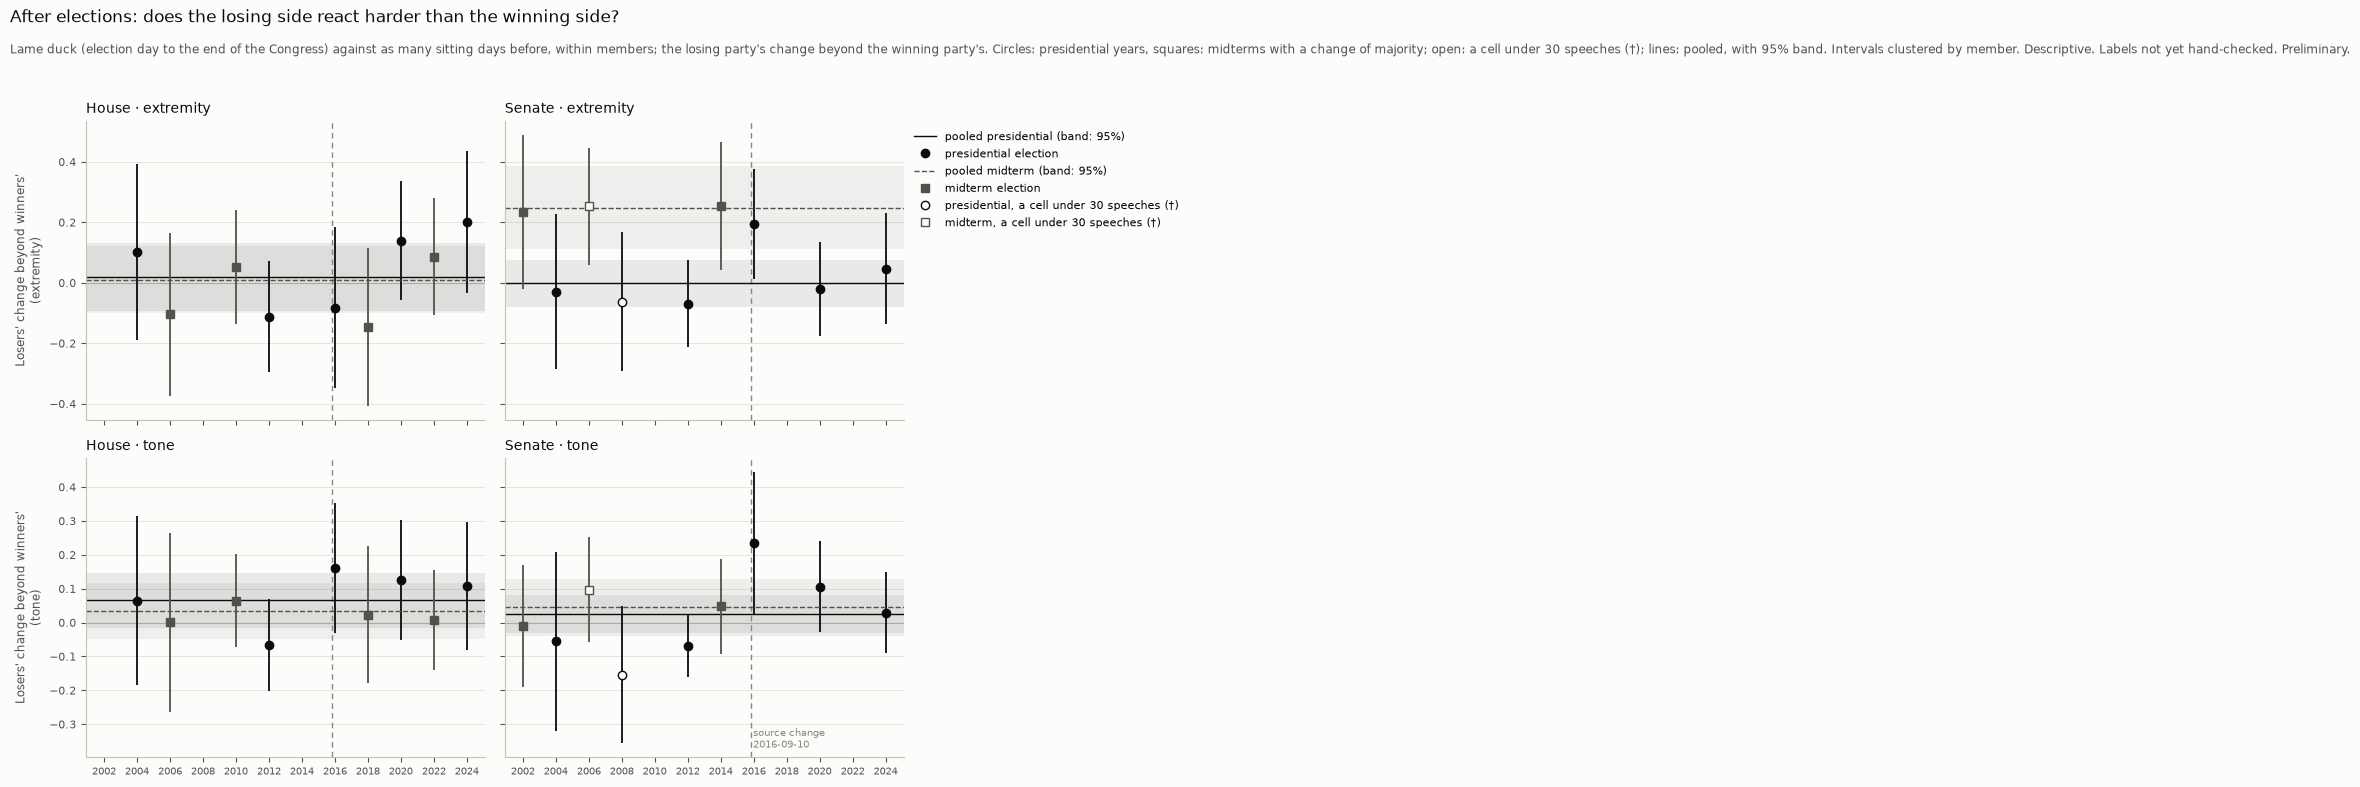

Windows (sitting days), speeches per party and period, and members speaking in both windows:


,election,chamber,n_days_before,n_days_after,before_from,before_to,after_from,after_to,short_before,cut_at_break,speeches D after,speeches D before,speeches R after,speeches R before,members in both D after,members in both R after
0,2002,H,7,7,2002-10-07,2002-10-17,2002-11-12,2002-11-22,False,True,18,49,23,50,6,3
1,2002,S,7,7,2002-10-08,2002-10-28,2002-11-12,2002-11-20,False,True,43,40,32,39,18,13
2,2004,H,9,9,2004-09-29,2004-10-11,2004-11-16,2004-12-08,False,True,33,70,33,57,12,9
3,2004,S,8,8,2004-10-04,2004-10-11,2004-11-16,2004-12-08,False,True,35,63,34,39,14,12
4,2006,H,7,7,2006-09-20,2006-09-29,2006-11-13,2006-12-08,False,True,41,66,42,68,9,17
5,2006,S,10,10,2006-09-18,2006-09-29,2006-11-09,2006-12-08,False,True,41,55,27,46,17,10
6,2008,H,2,2,2008-10-02,2008-10-03,2008-11-19,2008-12-10,False,True,4,18,9,12,2,1
7,2008,S,9,9,2008-09-23,2008-10-02,2008-11-17,2008-12-12,False,True,15,37,21,48,6,5
8,2010,H,17,17,2010-07-20,2010-09-29,2010-11-15,2010-12-22,False,True,109,141,81,116,40,29
9,2010,S,25,25,2010-07-20,2010-09-29,2010-11-15,2010-12-22,False,True,102,104,118,110,28,28


In [12]:
from src.config import SOURCE_BREAK_DATE
from src.deep_dive import (
    ELECTION_YEARS,
    corpus_sitting_days,
    election_day,
    election_outcomes,
    flag_small_election_cells,
    post_election_cell_sizes,
    post_election_data,
    post_election_effects,
    post_election_windows,
)
from src.deep_dive_plots import plot_post_election

EXPECTED_ELECTION_DAYS = [
    "2002-11-05", "2004-11-02", "2006-11-07", "2008-11-04", "2010-11-02", "2012-11-06",
    "2014-11-04", "2016-11-08", "2018-11-06", "2020-11-03", "2022-11-08", "2024-11-05",
]
assert [election_day(y).isoformat() for y in ELECTION_YEARS] == EXPECTED_ELECTION_DAYS, "election days off"
outcomes = election_outcomes()
print("Who lost, per election and chamber:")
display(outcomes)

sitting = corpus_sitting_days()
windows = post_election_windows(sitting, outcomes)
across = post_election_windows(sitting, outcomes, cut_at_break=False)
sides = windows.apply(lambda w: {d >= SOURCE_BREAK_DATE for d in (*w["before_days"], *w["after_days"])}, axis=1)
assert (sides.map(len) == 1).all(), "a main window crosses the source change"
changed = across[across["before_days"] != windows["before_days"]]
print("Before windows that change when they may cross the source change:",
      list(zip(changed["election"], changed["chamber"])))
assert list(zip(changed["election"], changed["chamber"])) == [("2016", "H")], "expected only 2016, House"
DAY_COLUMNS = ["before_days", "after_days"]
ROBUST = "before window across the source change"
tables["post_election_windows"] = pd.concat(
    [windows.drop(columns=DAY_COLUMNS).assign(variant="main"),
     changed.drop(columns=DAY_COLUMNS).assign(variant=ROBUST)], ignore_index=True)
tables["post_election_losers"] = outcomes

post = post_election_data(df, windows, outcomes)
election_sizes = post_election_cell_sizes(post)
election_effects = flag_small_election_cells(
    pd.concat([post_election_effects(post, value) for value in VALUES], ignore_index=True), election_sizes
).assign(variant="main")
post_across = post_election_data(df, across, outcomes)
sizes_across = post_election_cell_sizes(post_across)
effects_across = flag_small_election_cells(
    pd.concat([post_election_effects(post_across, value) for value in VALUES], ignore_index=True), sizes_across
).assign(variant=ROBUST)
touched = effects_across["chamber"].isin(changed["chamber"]) & (
    effects_across["election"].isin(changed["election"])
    | (effects_across["election"] == "pooled presidential"))
fig = plot_post_election(
    election_effects,
    "After elections: does the losing side react harder than the winning side?",
    subtitle=("Lame duck (election day to the end of the Congress) against as many sitting days before, within members; "
              "the losing party's change beyond the winning party's. Circles: presidential years, squares: midterms "
              "with a change of majority; open: a cell under 30 speeches (†); lines: pooled, with 95% band. "
              "Intervals clustered by member. Descriptive. " + SUB),
)
keep(fig, "deepdive_post_election")
tables["post_election_effects"] = pd.concat([election_effects, effects_across[touched]], ignore_index=True)
tables["post_election_cell_sizes"] = pd.concat(
    [election_sizes.assign(variant="main"),
     sizes_across[sizes_across["election"].isin(changed["election"])
                  & sizes_across["chamber"].isin(changed["chamber"])].assign(variant=ROBUST)],
    ignore_index=True)
counts = election_sizes.pivot_table(index=["election", "chamber"], columns=["party", "period"],
                                    values=["n", "n_members_both"], aggfunc="first")
counts.columns = [f"{'speeches' if v == 'n' else 'members in both'} {p} {q}" for v, p, q in counts.columns]
counts = counts.loc[:, ~counts.columns.str.startswith("members in both") | counts.columns.str.endswith("after")]
print("Windows (sitting days), speeches per party and period, and members speaking in both windows:")
display(windows.drop(columns=DAY_COLUMNS).merge(counts.reset_index(), on=["election", "chamber"]))

In [13]:
def dagger(table):
    text = with_ci(table, "coef", 3).where(table["coef"].notna(), "blank (see below)")
    return text + np.where(table["small_cell"], " †", "")


per = election_effects[election_effects["kind"] == "election"]
print("Per election: the losing side's change beyond the winning side's (coefficient [95% interval]; † a cell < 30):")
display(per.assign(coef_ci=dagger(per)).pivot_table(
    index=["election", "election_type", "chamber"], columns="value", values="coef_ci", aggfunc="first"))
print("Blank estimates:", per.loc[per["coef"].isna(), ["election", "chamber", "value", "note"]].values.tolist())
pooled = election_effects[election_effects["kind"].isin(["pooled", "trend"])]
print("Pooled per election type; trend = change of the effect per decade:")
display(pooled.assign(coef_ci=with_ci(pooled, "coef", 3)).pivot_table(
    index=["kind", "election_type", "chamber"], columns="value", values=["coef_ci", "n_members"], aggfunc="first"))
own = election_effects[(election_effects["kind"] == "own change") & (election_effects["status"] == "no change")]
print("Midterms without a change of majority: each party's own change, after minus before (described only):")
display(own.assign(coef_ci=dagger(own)).pivot_table(
    index=["election", "chamber", "party"], columns="value", values="coef_ci", aggfunc="first"))
robust = effects_across[touched & effects_across["kind"].isin(["election", "pooled", "trend"])]
print("Robustness, the House's 2016 before window across the source change:")
robust.assign(coef_ci=with_ci(robust, "coef", 3))[["value", "kind", "election", "chamber", "coef_ci", "n_members"]]

Per election: the losing side's change beyond the winning side's (coefficient [95% interval]; † a cell < 30):


value                                           extremity                       tone
election election_type chamber                                                      
2002     midterm       S          +0.234 [-0.021, +0.490]    -0.010 [-0.191, +0.171]
2004     presidential  H          +0.102 [-0.188, +0.392]    +0.065 [-0.184, +0.314]
                       S          -0.030 [-0.286, +0.227]    -0.056 [-0.319, +0.208]
2006     midterm       H          -0.104 [-0.373, +0.165]    +0.001 [-0.263, +0.264]
                       S        +0.253 [+0.060, +0.446] †  +0.097 [-0.058, +0.252] †
2008     presidential  H              blank (see below) †        blank (see below) †
                       S        -0.062 [-0.292, +0.168] †  -0.154 [-0.356, +0.049] †
2010     midterm       H          +0.053 [-0.136, +0.241]    +0.064 [-0.073, +0.202]
2012     presidential  H          -0.112 [-0.295, +0.071]    -0.067 [-0.203, +0.069]
                       S          -0.069 [-0.212, +0.074]    -0.069 [-0.160, +0.022]
2014     midterm       S          +0.253 [+0.041, +0.465]    +0.048 [-0.092, +0.188]
2016     presidential  H          -0.082 [-0.347, +0.184]    +0.161 [-0.032, +0.353]
                       S          +0.194 [+0.011, +0.377]    +0.233 [+0.022, +0.445]
2018     midterm       H          -0.146 [-0.408, +0.115]    +0.023 [-0.180, +0.225]
2020     presidential  H          +0.140 [-0.056, +0.335]    +0.126 [-0.051, +0.304]
                       S          -0.020 [-0.175, +0.134]    +0.106 [-0.029, +0.242]
2022     midterm       H          +0.086 [-0.107, +0.279]    +0.008 [-0.139, +0.155]
2024     presidential  H          +0.200 [-0.035, +0.434]    +0.107 [-0.082, +0.296]
                       S          +0.047 [-0.137, +0.230]    +0.029 [-0.091, +0.149]

Blank estimates: [['2008', 'H', 'extremity', 'under 2 members of a side speak in both windows'], ['2008', 'H', 'tone', 'under 2 members of a side speak in both windows']]
Pooled per election type; trend = change of the effect per decade:


coef_ci                          n_members     
value                                       extremity                     tone extremity tone
kind   election_type chamber                                                                 
pooled midterm       H        +0.010 [-0.101, +0.121]  +0.035 [-0.048, +0.117]       460  460
                     S        +0.249 [+0.112, +0.385]  +0.045 [-0.040, +0.130]       142  142
       presidential  H        +0.020 [-0.092, +0.132]  +0.065 [-0.016, +0.147]       562  562
                     S        -0.001 [-0.079, +0.077]  +0.026 [-0.030, +0.081]       191  191
trend  midterm       H        +0.030 [-0.142, +0.203]  -0.024 [-0.161, +0.113]       460  460
                     S        +0.012 [-0.247, +0.271]  +0.025 [-0.169, +0.218]       142  142
       presidential  H        +0.161 [+0.016, +0.305]  +0.077 [-0.049, +0.204]       562  562
                     S        +0.054 [-0.071, +0.179]  +0.085 [-0.020, +0.191]       191  191

Midterms without a change of majority: each party's own change, after minus before (described only):


value                                   extremity                       tone
election chamber party                                                      
2002     H       D      +0.050 [-0.365, +0.465] †  +0.147 [-0.247, +0.540] †
                 R      +0.100 [-0.266, +0.466] †  -0.225 [-0.505, +0.055] †
2010     S       D        -0.001 [-0.106, +0.104]    +0.039 [-0.031, +0.109]
                 R        -0.109 [-0.205, -0.013]    -0.140 [-0.193, -0.086]
2014     H       D        -0.012 [-0.202, +0.177]    -0.086 [-0.238, +0.065]
                 R        -0.074 [-0.201, +0.054]    -0.089 [-0.191, +0.014]
2018     S       D        -0.128 [-0.268, +0.011]    -0.012 [-0.123, +0.099]
                 R        -0.092 [-0.281, +0.097]    -0.054 [-0.192, +0.084]
2022     S       D        -0.151 [-0.279, -0.022]    -0.024 [-0.098, +0.050]
                 R        -0.006 [-0.123, +0.111]    -0.026 [-0.117, +0.064]

Robustness, the House's 2016 before window across the source change:


,value,kind,election,chamber,coef_ci,n_members
11,extremity,election,2016,H,"-0.125 [-0.377, +0.126]",167
23,extremity,pooled,pooled presidential,H,"+0.009 [-0.103, +0.120]",570
24,extremity,trend,pooled presidential,H,"+0.161 [+0.016, +0.306]",570
86,tone,election,2016,H,"+0.088 [-0.099, +0.275]",167
98,tone,pooled,pooled presidential,H,"+0.053 [-0.027, +0.133]",570
99,tone,trend,pooled presidential,H,"+0.078 [-0.049, +0.204]",570


**Reading it (4c).** Preliminary and descriptive; one model (DeepSeek), labels not
hand-checked.

- **Pooled, the losing side reacts no harder in tone than the winning side.** After minus
  before, losers beyond winners: presidential years House +0.065 [−0.016, +0.147], Senate
  +0.026 [−0.030, +0.081]; midterms House +0.035 [−0.048, +0.117], Senate +0.045 [−0.040,
  +0.130]. In extremity likewise none, except one: **after a midterm, the party that loses the
  Senate speaks further out than the one that wins it**, +0.249 [+0.112, +0.385], carried by
  2002, 2006 and 2014 (each about +0.25; 2006 rests on a cell under 30, †).
- **Single elections are imprecise.** Of 19 election × chamber comparisons, clear intervals in
  tone only for the Senate in 2016 (+0.233 [+0.022, +0.445]); in extremity for the Senate in
  2006 (†), 2014 and 2016 (+0.194 [+0.011, +0.377]). House 2008 is blank: one Republican and two
  Democrats speak in both windows.
- **Over time:** the reaction grows in only one series. In the House after presidential
  elections the losers' extra move outward rises by +0.161 [+0.016, +0.305] per decade (2004
  +0.10, 2012 −0.11, 2016 −0.08, 2020 +0.14, 2024 +0.20, none clear on its own). Tone in presidential years
  points the same way (House +0.077 [−0.049, +0.204], Senate +0.085 [−0.020, +0.191] per decade)
  but is not clear. A hint, not a finding.
- **Midterms without a change of majority** (described only): after 2010 the Senate's
  Republicans, who gained seats but not the majority, spoke milder (tone −0.140 [−0.193,
  −0.086]) and less far out (−0.109 [−0.205, −0.013]); after 2022 the Senate's Democrats less
  far out (−0.151 [−0.279, −0.022]). The other own changes are not clear.
- **Robustness:** with the House's 2016 before window reaching across the source change (three
  Stanford days added), 2016 moves (tone +0.088 instead of +0.161, extremity −0.125 instead of
  −0.082, both unclear); the pooled values stay unclear and the trend does not move (+0.161 per
  decade either way).
- **Limits.** The weeks after an election are short of sittings: 2 to 27 sitting days a side
  (House 2008: two); 9 of the 96 party × period cells hold fewer than 30 speeches, all in
  2002–2008 (†). Congress rarely sits in October, so the before window often reaches back
  into the summer (2010 and 2012 from July): it is the last sitting weeks before the election,
  not the end of the campaign. Few members speak in both windows (1 to 40 per party and
  election), and the lame duck has its own agenda (budgets, nominations, farewells), which the
  comparison of the two sides removes only where it hits both alike. Presidents and majorities
  come from the constants. The 2026 election and the 120th Congress lie outside the data — an
  outlook, not a gap to fill.

## 5. Naming the other party: chamber minority or opposition?

**Question.** 09 found that naming the other party rose steeply in the Senate and seems to
follow minority status in the House. Within the same member, is naming the other party
driven by being in the chamber minority, by being out of the White House, or both?

**How.** The 0/1 flag "the speech names the other party" (09's `other_party` list,
precision 98%). A linear probability model as 08's model C: member fixed effects, linear
trend, `opposition` and `chamber_minority`, per party × chamber, clustered by member. Main
basis: substantive `d100k` speeches; robustness: the whole corpus (every speech type), as
09's power words. Coefficients are changes in the share of speeches (0.05 = 5 points).

Corpus: 580,007 speeches, read in 9.7 min


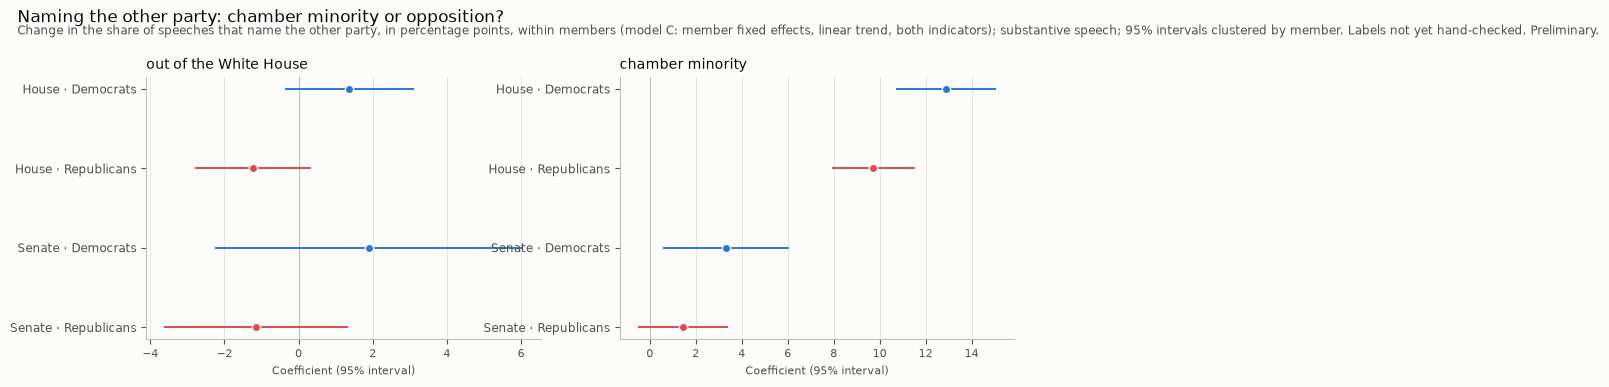

term              chamber_minority                               opposition                   
basis                       corpus     d100k substantive             corpus  d100k substantive
chamber party                                                                                 
H       D      +10.0 [+8.7, +11.2]  +12.9 [+10.7, +15.1]  -0.4 [-1.3, +0.4]  +1.4 [-0.4, +3.1]
        R        +8.5 [+7.4, +9.5]    +9.7 [+7.9, +11.5]  -0.2 [-0.9, +0.5]  -1.2 [-2.8, +0.3]
S       D        +3.3 [+1.9, +4.8]     +3.3 [+0.6, +6.1]  +0.7 [-2.7, +4.0]  +1.9 [-2.3, +6.0]
        R        +3.1 [+1.2, +5.0]     +1.4 [-0.5, +3.4]  -0.1 [-1.9, +1.6]  -1.1 [-3.6, +1.3]

In [14]:
texts = speech_texts(df["speech_id"].tolist())
hits = keyword_hits(df.assign(text=df["speech_id"].map(texts)))
del texts
names = df.assign(other_party=hits["other_party"])
power = names_power_effects(names).assign(basis="d100k substantive")

start = time.time()
corpus = load_corpus_keyword_hits()
timings["corpus keyword pass"] = time.time() - start
corpus = add_chamber_control(corpus[["speech_id", "date", "member_key", "party", "chamber", "congress_number",
                                     "in_opposition", "other_party"]])
corpus["opposition"] = corpus["in_opposition"].astype(float)
power_corpus = names_power_effects(corpus).assign(basis="corpus")
print(f"Corpus: {len(corpus):,} speeches, read in {timings['corpus keyword pass'] / 60:.1f} min")
del corpus

shown = power[power["term"].isin(["opposition", "chamber_minority"])]
shown = shown.assign(value=shown["term"].map({"opposition": "out of the White House", "chamber_minority": "chamber minority"}),
                     term="effect", coef=100 * shown["coef"], ci_low=100 * shown["ci_low"], ci_high=100 * shown["ci_high"])
fig = plot_term_coefficients(
    shown, "effect", "Naming the other party: chamber minority or opposition?",
    subtitle=("Change in the share of speeches that name the other party, in percentage points, within members (model C: "
              f"member fixed effects, linear trend, both indicators); substantive speech; 95% intervals clustered by member. {SUB}"),
)
keep(fig, "deepdive_names_other_party_power")
tables |= {"names_other_party_power": power, "names_other_party_power_corpus": power_corpus}
both = pd.concat([power, power_corpus])
both = both[both["term"] != "congress_number"]
both.assign(points_ci=with_ci(both.assign(coef=100 * both["coef"], ci_low=100 * both["ci_low"],
                                          ci_high=100 * both["ci_high"]), "coef", 1)).pivot_table(
    index=["chamber", "party"], columns=["term", "basis"], values="points_ci", aggfunc="first")

**Reading it (5).** Preliminary; changes in the share of speeches, in percentage points,
within members.

- **Naming the other party follows the chamber minority, not the White House.** In the
  House, the same member names the other party more often once their party is in the
  chamber minority: Democrats +12.9 [+10.7, +15.1], Republicans +9.7 [+7.9, +11.5]. In the
  Senate the effect is smaller (Democrats +3.3 [+0.6, +6.1]; Republicans +1.4
  [−0.5, +3.4]).
- Being out of the White House shows no clear effect in either chamber or party (between
  −1.2 and +1.9 points, every interval across zero).
- The trend adds 1–2 points per Congress in every group.
- **The whole corpus** gives the same picture: chamber minority House +10.0 / +8.5, Senate
  +3.3 / +3.1; opposition ≈ 0.

## 6. Swing states: the own party's margin, and within the same senator

**Question.** 09 measured a state's competitiveness without sign. Here the sign matters: are
senators from their own party's strongholds further out than senators from states that lean
to the other party — and does that hold within the same senator when their state's margin
changes?

**How.** `own_margin` = the two-party share of the senator's own party − 0.5, averaged over
the last two presidential elections before the Congress (the same data and rule as 09:
MIT Election Lab county returns; for the 107th and 108th only the 2000 election). Positive:
a stronghold of the own party; negative: the state leans to the other party. (a) As in 09,
extremity and tone relative to party × chamber × Congress, now by `own_margin`: linear per
10 points within party × Congress, and in terciles over the party's senators in each
Congress (decided 2026-11-03); 09's absolute margin in the same table for comparison. (b)
Within the same senator: senator fixed effects and the party's Congress effects; only
senators whose state's margin changes identify it, and how many there are and how much it
changes is reported.

**Limits.** Voters' preferences and competition cannot be told apart: a stronghold is both.
Senate only (no district results for the House).

Senate speeches without a margin: 0


The absolute margin reproduces notebook 09.


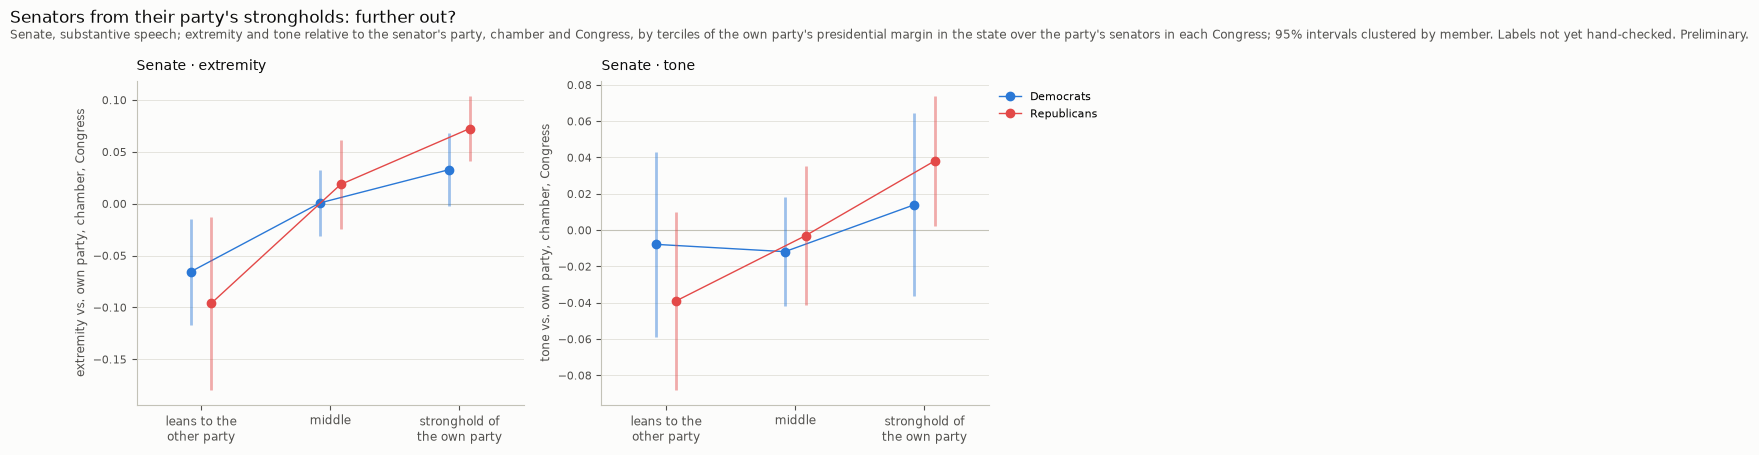

own_tercile                          low                   middle                     high
value     party                                                                           
extremity D      -0.066 [-0.117, -0.014]  +0.001 [-0.031, +0.033]  +0.033 [-0.002, +0.068]
          R      -0.096 [-0.180, -0.012]  +0.018 [-0.025, +0.062]  +0.072 [+0.041, +0.104]
tone      D      -0.008 [-0.059, +0.043]  -0.012 [-0.042, +0.018]  +0.014 [-0.036, +0.064]
          R      -0.039 [-0.088, +0.010]  -0.003 [-0.041, +0.035]  +0.038 [+0.002, +0.074]

variant                    absolute (09)               own margin own margin, within senator
value     party                                                                             
extremity D      +0.031 [-0.022, +0.084]  +0.070 [+0.038, +0.103]    +0.043 [-0.027, +0.113]
          R      +0.101 [+0.048, +0.155]  +0.118 [+0.056, +0.179]    +0.048 [-0.017, +0.112]
tone      D      +0.031 [-0.021, +0.084]  +0.023 [-0.012, +0.057]    +0.023 [-0.037, +0.083]
          R      +0.044 [+0.007, +0.082]  +0.055 [+0.013, +0.097]    +0.019 [-0.024, +0.063]

,party,n_senators,n_with_variation,median_range_points,mean_range_points,max_range_points
0,D,123,94,3.727,4.327,14.410
1,R,132,108,2.590,3.293,11.883


In [15]:
shares = state_two_party_share()
check = shares.set_index(["state", "year"])["d_share"]
assert round(check[("PA", 2020)], 3) == 0.506 and round(check[("FL", 2000)], 3) == 0.500, "state shares off"
leans = state_leans(shares, CONGRESSES)
margins = state_margins(shares, CONGRESSES)
senate = df[df["chamber"] == "S"].assign(
    extremity_vs_cell=relative_to_cell(df, "extremity")[df["chamber"] == "S"],
    tone_vs_cell=relative_to_cell(df, "tone")[df["chamber"] == "S"],
)
senate = senate.merge(margins[["state", "congress_number", "margin", "tercile"]],
                      on=["state", "congress_number"], how="left", validate="m:1")
senate = add_own_margin(senate, leans)
print(f"Senate speeches without a margin: {senate['own_margin'].isna().sum()}")
senate = senate.dropna(subset=["own_margin"])
own_means, own_linear = own_margin_effects(senate)
abs_means, abs_linear = swing_state_effects(senate)
committed = pd.read_csv(METRICS_DIR / f"deepdive_swing_states_linear_{RUN}.csv")
check = abs_linear.merge(committed, on=["party", "value"], suffixes=("", "_09"))
assert np.allclose(check["coef"], check["coef_09"], rtol=1e-10), "absolute margin does not reproduce 09"
print("The absolute margin reproduces notebook 09.")
within, variation = own_margin_within(senate)
fig = plot_own_margin(
    own_means, "Senators from their party's strongholds: further out?",
    subtitle=("Senate, substantive speech; extremity and tone relative to the senator's party, chamber and Congress, by "
              "terciles of the own party's presidential margin in the state over the party's senators in each Congress; "
              f"95% intervals clustered by member. {SUB}"),
)
keep(fig, "deepdive_swing_states_own_margin")
tables |= {
    "swing_states_own_margin": pd.concat([
        own_means.assign(variant="own margin", kind="tercile"),
        own_linear.assign(variant="own margin", kind="linear per 10 points"),
        abs_means.assign(variant="absolute margin (09)", kind="tercile"),
        abs_linear.assign(variant="absolute margin (09)", kind="linear per 10 points"),
    ], ignore_index=True),
    "swing_states_within": pd.concat([within.assign(kind="within senator"), variation.assign(kind="variation")],
                                     ignore_index=True),
}
display(own_means.assign(mean_ci=with_ci(own_means, digits=3)).pivot(
    index=["value", "party"], columns="own_tercile", values="mean_ci")[["low", "middle", "high"]])
lin = pd.concat([own_linear.assign(variant="own margin"), abs_linear.assign(variant="absolute (09)"),
                 within.assign(variant="own margin, within senator")])
display(lin.assign(coef_ci=with_ci(lin, "coef", 3)).pivot_table(
    index=["value", "party"], columns="variant", values="coef_ci", aggfunc="first"))
variation

**Reading it (6).** Preliminary; Senate only. Voters' preferences and competition cannot be
separated: a stronghold of the own party is both.

- **Senators from their party's strongholds speak further out than senators from states
  leaning to the other party**, relative to their party, chamber and Congress. Republicans:
  lowest third −0.096 [−0.180, −0.012], highest +0.072 [+0.041, +0.104]; Democrats −0.066
  [−0.117, −0.014] against +0.033 [−0.002, +0.068].
- Per 10 points of own margin: Democrats +0.070 [+0.038, +0.103], Republicans +0.118
  [+0.056, +0.179]. The signed margin shows the pattern for Democrats too, which 09's
  absolute margin did not (+0.031 [−0.022, +0.084]). Tone: Republicans +0.055
  [+0.013, +0.097], Democrats not clear.
- **Within the same senator, no clear association** (Democrats +0.043 [−0.027, +0.113],
  Republicans +0.048 [−0.017, +0.112]). Most senators' margin does change (94 of 123
  Democrats, 108 of 132 Republicans), but only a little: median range 3.7 and 2.6 points.
  The pattern is therefore one between senators, not shown within a senator.

## 7. Topic blocks around the events

**Question.** Around 09's six events, which topic blocks moved: did the debate shift
toward a block (agenda), did the parties' gap within a block change, did the tone change?

**How.** The same events and windows as 09 (`EVENTS`, `event_windows`: six months a side,
cut at the Congress boundary; the Iraq window of 76 days accepted in A8). Per event and
chamber, before against after, for all five blocks: (a) the block's share of each party's
policy debates (linear probability model, party × period), (b) the change of R − D within
the block, (c) each party's change in tone within the block (saturated model party ×
period × block). Clustered by member. Cells under 30 speeches are kept and marked †, as in
09; a contrast with an empty cell is left out ("–"). Only clear intervals are read.

**Limits.** With five blocks instead of two groups, many cells are small; most estimates
here are imprecise.

116 of 240 party × period × block cells under 30 speeches (0 empty); 113 of 300 estimates rest on a small cell, 0 have an empty one.


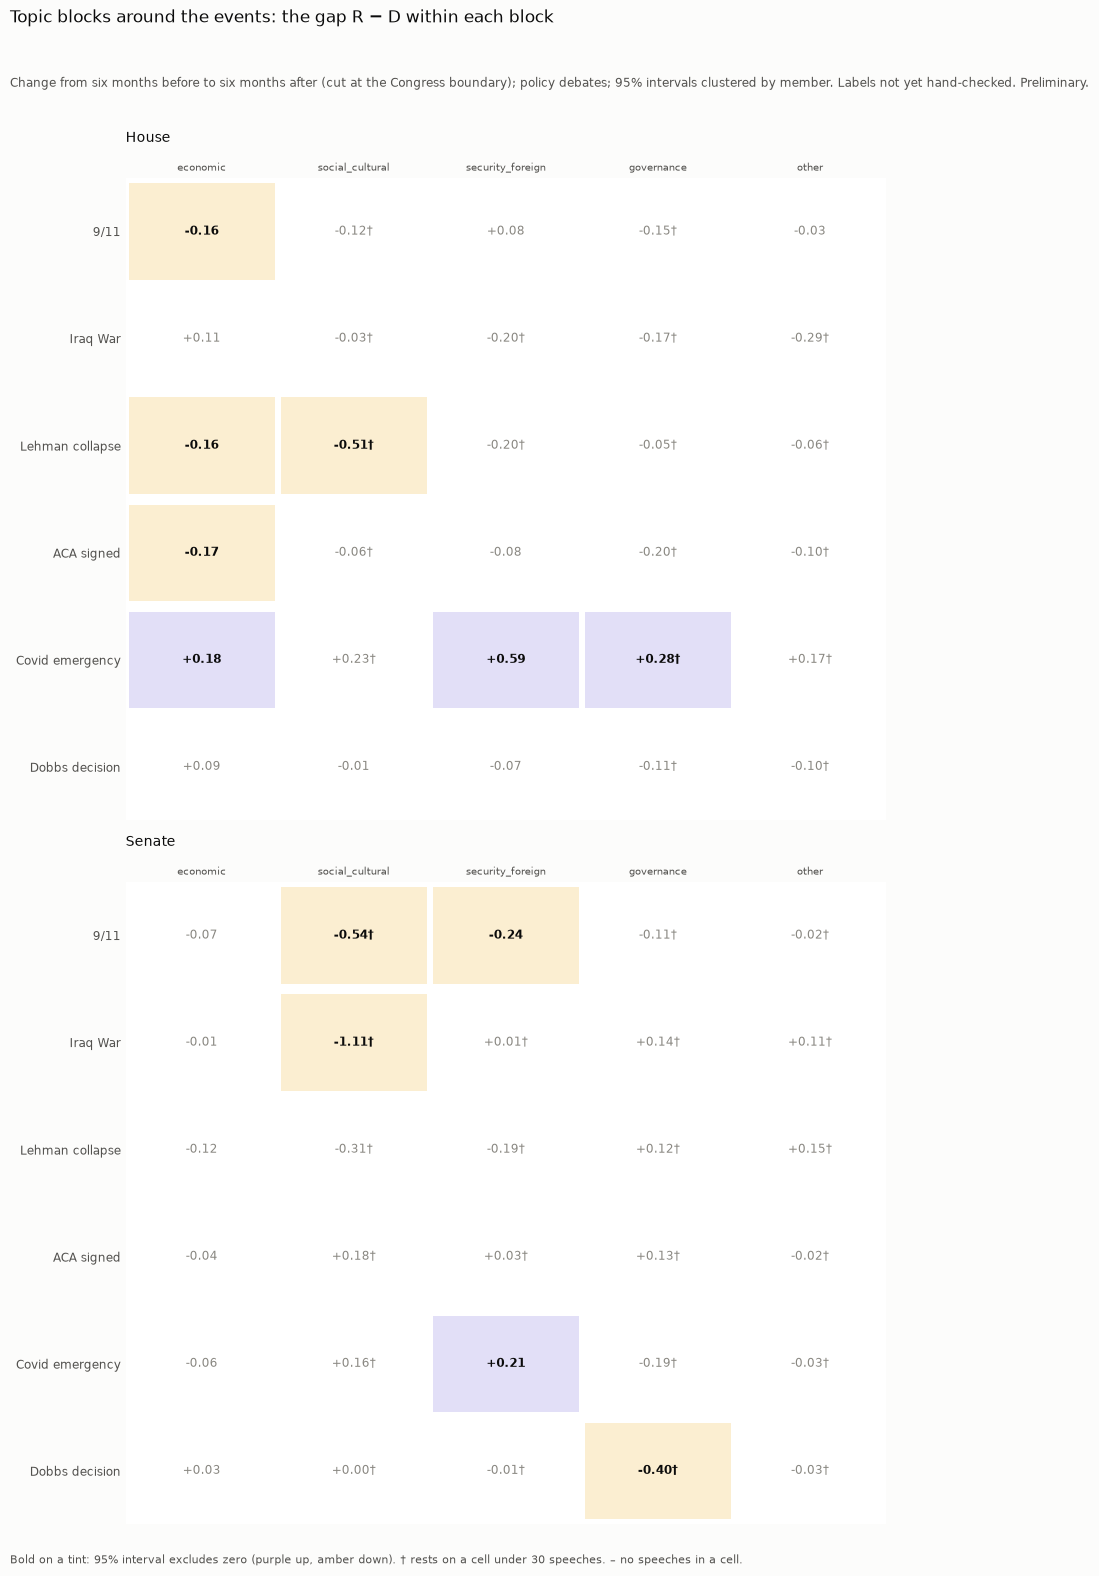

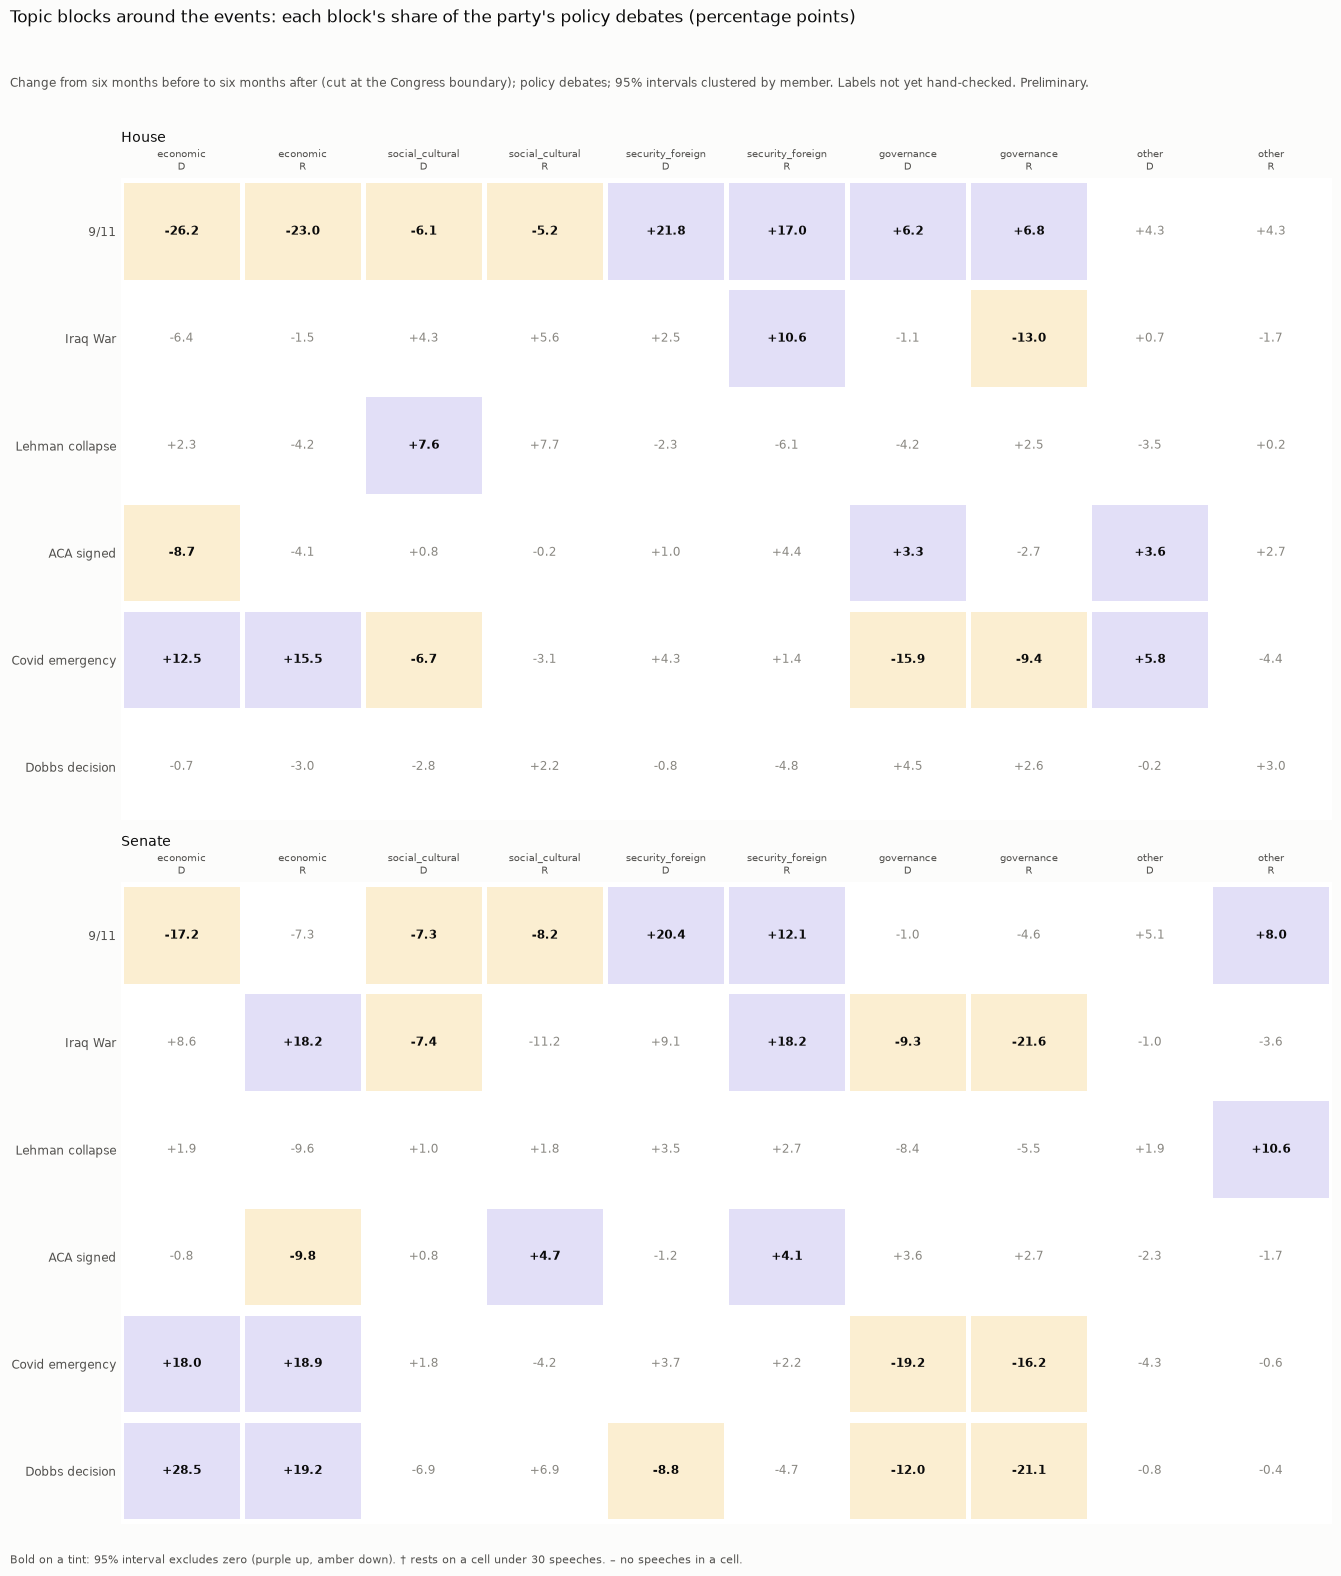

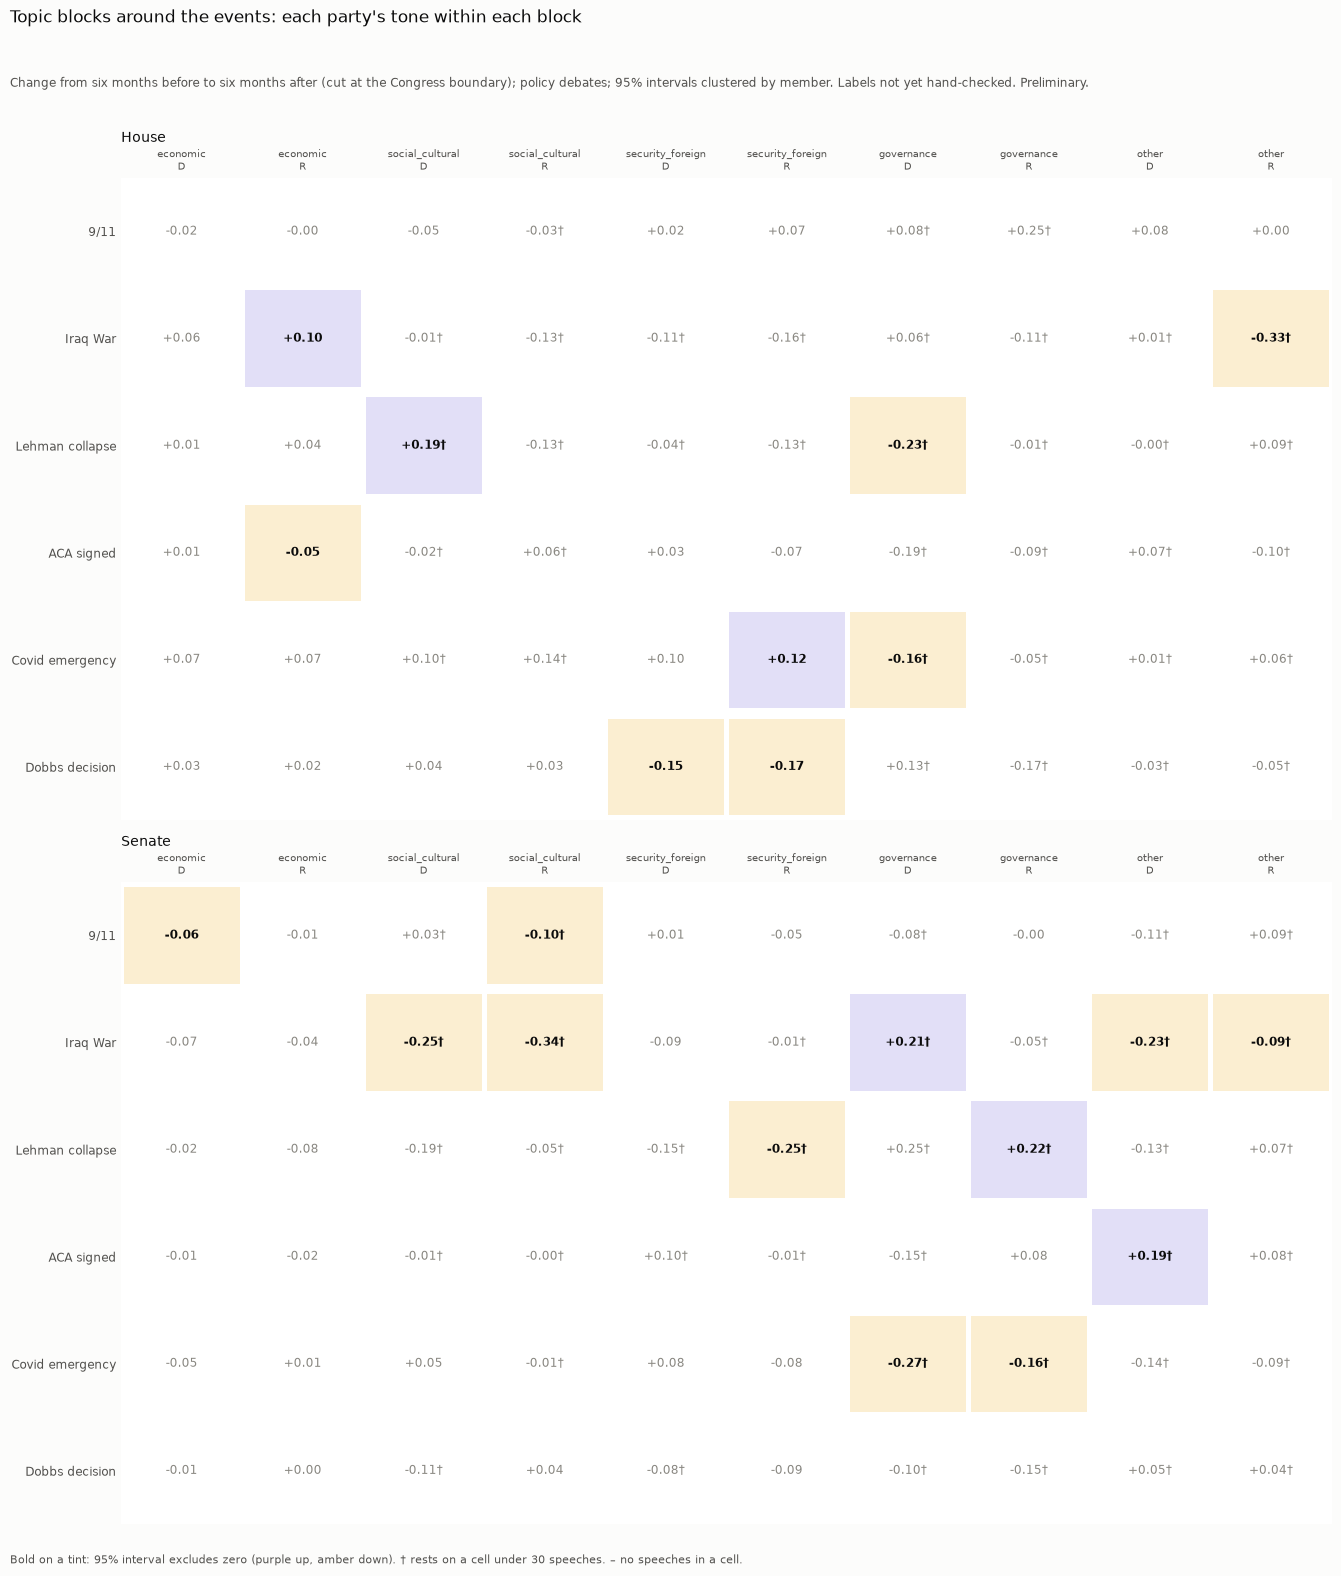

77 estimates with an interval clear of zero:


,event,chamber,measure,party,topic_block,estimate,ci_low,ci_high,small_cell
0,9/11,H,gap,R−D,economic,-0.157,-2.884e-01,-2.574e-02,False
2,9/11,H,agenda,D,economic,-0.262,-3.345e-01,-1.894e-01,False
4,9/11,H,agenda,R,economic,-0.230,-3.053e-01,-1.543e-01,False
7,9/11,H,agenda,D,social_cultural,-0.061,-1.044e-01,-1.753e-02,False
9,9/11,H,agenda,R,social_cultural,-0.052,-9.124e-02,-1.195e-02,False
12,9/11,H,agenda,D,security_foreign,0.218,1.605e-01,2.754e-01,False
14,9/11,H,agenda,R,security_foreign,0.170,1.007e-01,2.393e-01,False
17,9/11,H,agenda,D,governance,0.062,1.809e-02,1.063e-01,False
19,9/11,H,agenda,R,governance,0.068,3.227e-02,1.043e-01,False
26,9/11,S,tone,D,economic,-0.059,-1.110e-01,-6.224e-03,False


In [16]:
windows = event_windows()
ACCEPT_SHORT_WINDOWS = ("Iraq War",)  # A8
short = windows[windows["too_short"] & ~windows["event"].isin(ACCEPT_SHORT_WINDOWS)]
if len(short):
    raise RuntimeError(f"windows under {EVENT_MIN_DAYS} days a side: {short['event'].tolist()}")
block_sizes = event_block_cell_sizes(policy, windows)
block_effects = flag_small_block_cells(event_block_effects(policy, windows), block_sizes)
print(f"{block_sizes['below_min'].sum()} of {len(block_sizes)} party × period × block cells under {TOPIC_MIN_CELL} "
      f"speeches ({(block_sizes['n'] == 0).sum()} empty); "
      f"{block_effects['small_cell'].sum()} of {len(block_effects)} estimates rest on a small cell, "
      f"{block_effects['estimate'].isna().sum()} have an empty one.")
for measure, label in (("gap", "the gap R − D within each block"),
                       ("agenda", "each block's share of the party's policy debates (percentage points)"),
                       ("tone", "each party's tone within each block")):
    fig = plot_event_block_grid(
        block_effects, measure, f"Topic blocks around the events: {label}",
        subtitle=(f"Change from six months before to six months after (cut at the Congress boundary); policy debates; "
                  f"95% intervals clustered by member. {SUB}"),
    )
    keep(fig, f"deepdive_event_blocks_{measure}")
tables |= {"event_blocks": block_effects, "event_blocks_cell_sizes": block_sizes}
clear = block_effects[(block_effects["ci_low"] > 0) | (block_effects["ci_high"] < 0)]
print(f"{len(clear)} estimates with an interval clear of zero:")
clear[["event", "chamber", "measure", "party", "topic_block", "estimate", "ci_low", "ci_high", "small_cell"]]

**Reading it (7).** Preliminary and imprecise: 116 of 240 cells hold fewer than 30
speeches, and 113 of 300 estimates rest on such a cell (†); only clear intervals are read.

- **The agenda moved as the events suggest.** After 9/11 the share of policy debates on
  security-foreign rose by 12–22 points in both parties and chambers, and the economic share
  fell (House −26 / −23). After the Covid emergency the economic share rose (House +13 /
  +16, Senate +18 / +19) and governance fell. After Dobbs, the social-cultural share shows
  no clear rise; the Senate's debates moved toward economic topics (+29 / +19), which falls
  in the summer of 2022.
- **The gap inside blocks:** after 9/11 it narrowed in the House's economic block (−0.16)
  and the Senate's security-foreign block (−0.24); after the ACA and Lehman in the House's
  economic block (−0.17, −0.16). After the Covid emergency it widened in the House
  (economic +0.18, security-foreign +0.59, governance +0.28†) and in the Senate's
  security-foreign block (+0.21). The large Senate values for social-cultural after 9/11
  and the Iraq War (−0.54†, −1.11†) rest on small cells.
- **Tone** changes are mostly on small cells; Dobbs comes with a milder tone in the House's
  security-foreign block for both parties (−0.15 / −0.17).
- Iraq (76 days a side) and Lehman (110 days, recess) remain the weakest cases.

## 8. New members against continuing ones

**Question.** 09 compared each entry cohort with its party's mean — a mean that includes the
newcomers themselves. Against the members already there, do newcomers stand out?

**How.** The same definition as 09's B: a member is new in the first Congress they serve in
either chamber (A4, from Voteview's whole history), from the 107th on; ICPSRs with earlier
service under another ICPSR (party switchers) are left out entirely. The difference new −
continuing in extremity within party × chamber × Congress, clustered by member: per cohort,
pooled per party × chamber, and per presidency. 09's comparison with the party mean sits in
the same table.

17 switchers left out; 09's cohort means reproduced.


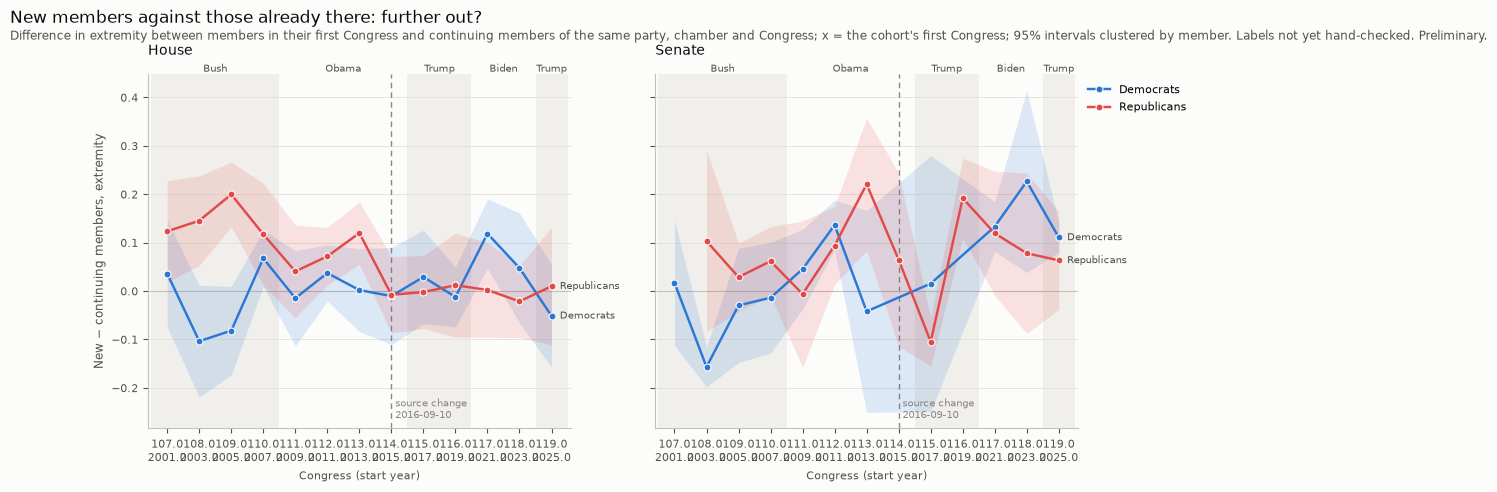

,level,chamber,party,presidency,coef_ci,p,n_new_members,n_members
49,pooled,H,D,NaN,"+0.006 [-0.023, +0.034]",7.053e-01,350,579
50,pooled,H,R,NaN,"+0.057 [+0.031, +0.083]",2.032e-05,458,679
51,pooled,S,D,NaN,"+0.027 [-0.027, +0.080]",3.311e-01,43,119
52,pooled,S,R,NaN,"+0.099 [+0.035, +0.163]",2.510e-03,44,123
53,presidency,H,D,Biden 2021-2024,"+0.078 [+0.005, +0.151]",3.537e-02,54,237
54,presidency,H,D,Bush 2001-2008,"-0.004 [-0.051, +0.043]",8.668e-01,84,285
55,presidency,H,D,Obama 2009-2016,"-0.002 [-0.053, +0.049]",9.347e-01,102,322
56,presidency,H,D,Trump 2017-2020,"+0.004 [-0.051, +0.058]",8.985e-01,79,252
57,presidency,H,D,Trump 2025-2026,"-0.051 [-0.158, +0.055]",3.451e-01,31,191
58,presidency,H,R,Biden 2021-2024,"-0.010 [-0.071, +0.051]",7.448e-01,86,245


coef_ci                                                                            n_new_members              
chamber                        H                                                 S                                      H        S     
party                          D                        R                        D                        R             D   R    D    R
cohort                                                                                                                                 
107.0    +0.036 [-0.074, +0.147]  +0.124 [+0.019, +0.228]  +0.017 [-0.112, +0.147]                      NaN            13  30    5  NaN
108.0    -0.103 [-0.219, +0.012]  +0.145 [+0.053, +0.238]  -0.157 [-0.198, -0.115]  +0.103 [-0.084, +0.290]            14  31    1    5
109.0    -0.082 [-0.173, +0.010]  +0.200 [+0.133, +0.266]  -0.030 [-0.148, +0.088]  +0.029 [-0.042, +0.099]            16  21    2    1
110.0    +0.068 [+0.009, +0.126]  +0.117 [+0.012, +0.223]  -0.014 [-0.128, +0.100]  +0.062 [-0.009, +0.133]            41  16    6    2
111.0    -0.015 [-0.113, +0.084]  +0.041 [-0.055, +0.136]  +0.046 [-0.037, +0.128]  -0.006 [-0.157, +0.145]            34  25   10    4
112.0    +0.037 [-0.021, +0.095]  +0.072 [+0.012, +0.131]  +0.136 [+0.085, +0.188]  +0.094 [+0.014, +0.175]            12  79    1    5
113.0    +0.002 [-0.083, +0.088]  +0.120 [+0.056, +0.184]  -0.042 [-0.250, +0.167]  +0.221 [+0.084, +0.358]            40  35    7    3
114.0    -0.010 [-0.111, +0.090]  -0.008 [-0.087, +0.071]                      NaN  +0.065 [-0.114, +0.244]            16  42  NaN    6
115.0    +0.029 [-0.068, +0.126]  -0.002 [-0.078, +0.073]  +0.015 [-0.249, +0.280]  -0.105 [-0.155, -0.055]            25  33    5    1
116.0    -0.012 [-0.074, +0.050]  +0.012 [-0.095, +0.119]                      NaN  +0.192 [+0.109, +0.274]            54  31  NaN    5
117.0    +0.119 [+0.047, +0.190]  +0.002 [-0.095, +0.100]  +0.133 [+0.082, +0.185]  +0.119 [-0.009, +0.248]            20  47    3    2
118.0    +0.048 [-0.066, +0.161]  -0.021 [-0.096, +0.053]  +0.227 [+0.038, +0.415]  +0.078 [-0.087, +0.244]            34  39    2    4
119.0    -0.051 [-0.158, +0.055]  +0.010 [-0.111, +0.131]  +0.111 [+0.081, +0.141]  +0.063 [-0.038, +0.165]            31  29    1    6

In [17]:
members = add_background(df, member_background())
members["extremity_vs_cell"] = relative_to_cell(members, "extremity")
switchers = prior_service_switchers()
in_data = switchers[switchers["icpsr"].isin(members["icpsr"].dropna().astype(int))]
vs = cohort_vs_continuing(members, exclude_icpsr=in_data["icpsr"].tolist())
old = cohort_extremity(members, exclude_icpsr=in_data["icpsr"].tolist())
committed = pd.read_csv(METRICS_DIR / f"deepdive_cohort_extremity_{RUN}.csv")
check = old.merge(committed, on=["chamber", "party", "cohort"], suffixes=("", "_09"))
assert len(check) == len(committed) and np.allclose(check["mean"], check["mean_09"], rtol=1e-10)
print(f"{len(in_data)} switchers left out; 09's cohort means reproduced.")
per_cohort = vs[vs["level"] == "cohort"]
fig = plot_party_positions(
    per_cohort.rename(columns={"cohort": "congress_number", "coef": "mean"}),
    "New − continuing members, extremity",
    "New members against those already there: further out?",
    subtitle=("Difference in extremity between members in their first Congress and continuing members of the same party, "
              f"chamber and Congress; x = the cohort's first Congress; 95% intervals clustered by member. {SUB}"),
)
keep(fig, "deepdive_cohort_vs_continuing")
tables["cohort_vs_continuing"] = pd.concat(
    [vs.assign(variant="new − continuing"),
     old.rename(columns={"mean": "coef"}).assign(variant="new vs. party mean (09)", level="cohort")],
    ignore_index=True,
)
pooled = vs[vs["level"] != "cohort"]
display(pooled.assign(coef_ci=with_ci(pooled, "coef", 3))[
    ["level", "chamber", "party", "presidency", "coef_ci", "p", "n_new_members", "n_members"]])
per_cohort.assign(coef_ci=with_ci(per_cohort, "coef", 3)).pivot(
    index="cohort", columns=["chamber", "party"], values=["coef_ci", "n_new_members"])

**Reading it (8).** Preliminary.

- **New House and Senate Republicans stand further out than the Republicans already there**:
  pooled +0.057 [+0.031, +0.083] (House) and +0.099 [+0.035, +0.163] (Senate). New
  Democrats do not differ (House +0.006 [−0.023, +0.034], Senate +0.027 [−0.027, +0.080]).
- **For House Republicans this is a pattern of the earlier years:** under Bush +0.153
  [+0.108, +0.198] and under Obama +0.059 [+0.019, +0.099], but not from 2017 on (Trump
  +0.004, Biden −0.010, 2025 +0.010). This matches 09: from the 114th on newcomers no
  longer stand out — the members already there had moved out too.
- New House Democrats under Biden stand out slightly (+0.078 [+0.005, +0.151]).
- Senate cohorts are small (1–18 new members per presidency); single values there are not
  read.

## 9. The centre disappears

**Question.** How fast did the share of members near the centre fall, and does it depend on
where the centre is drawn?

**How.** Members with at least 10 substantive speeches in a Congress (A3, A5), each by
their mean ideology; the share with |mean| < 0.2 per party × chamber × Congress (09's
robustness definition of a moderate), and at 0.15 and 0.25. One member bootstrap,
`dissent_table`'s draw for draw, so the 0.2 band must reproduce 09's `share_centrist`
with its interval.

**Limits.** This measure moves mechanically with the gap: when the parties' means move
apart, fewer members sit near zero. It is not an independent measurement of polarization.

centrist bootstrap: 1.2 min
The 0.2 band reproduces notebook 09 (values and intervals).


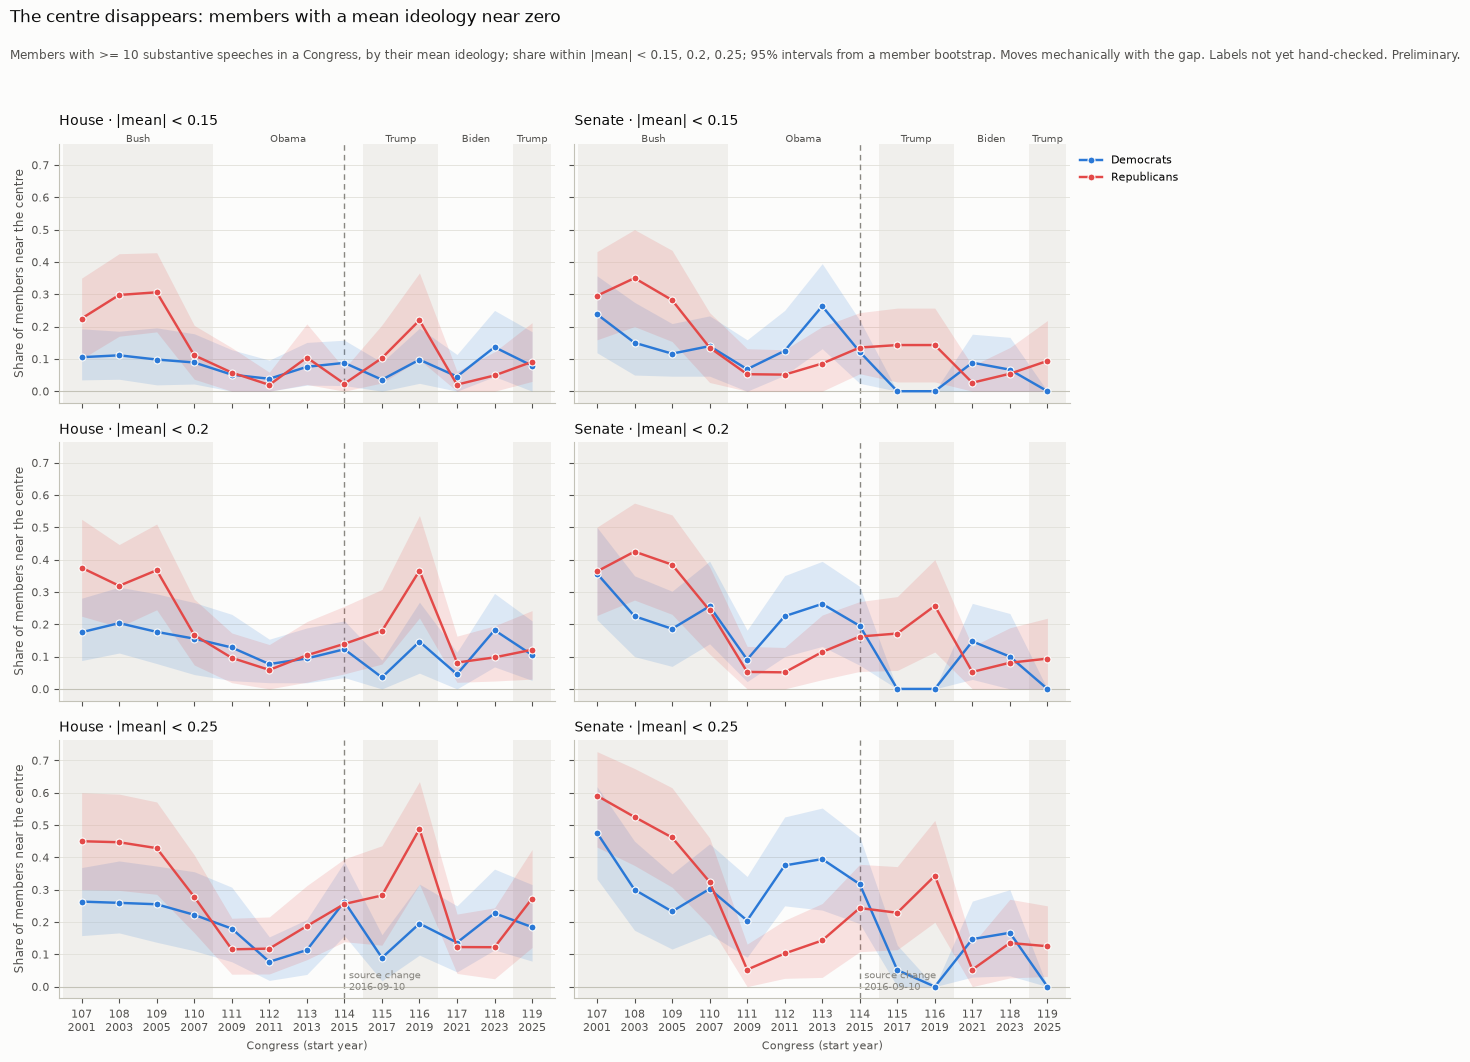

chamber                          H                                       S                                       H                                       S                                       H  \
party                            D                   R                   D                   R                   D                   R                   D                   R                   D   
band                          0.15                0.15                0.15                0.15                0.20                0.20                0.20                0.20                0.25   
congress_number                                                                                                                                                                                      
107              10.5% [3.5, 19.3]  22.5% [10.0, 35.0]  23.8% [11.9, 35.7]  29.5% [15.9, 43.2]   17.5% [8.8, 28.1]  37.5% [22.5, 52.5]  35.7% [21.4, 50.0]  36.4% [22.7, 50.1]  26.3% [15.8, 36.8]   
108              11.1% [3.7, 18.6]  29.8% [17.0, 42.6]   15.0% [5.0, 27.5]  35.0% [20.0, 50.0]  20.4% [11.1, 31.5]  31.9% [19.1, 44.7]  22.5% [10.0, 35.0]  42.5% [27.5, 57.5]  25.9% [16.6, 38.9]   
109               9.8% [2.0, 19.6]  30.6% [18.4, 42.9]   11.6% [4.7, 20.9]  28.2% [15.4, 43.6]   17.6% [7.8, 29.4]  36.7% [24.5, 51.0]   18.6% [7.0, 30.2]  38.5% [23.1, 53.8]  25.5% [13.7, 37.3]   
110               8.9% [2.2, 17.8]   11.1% [3.7, 20.4]   14.0% [4.7, 23.3]   13.5% [2.7, 24.3]   15.6% [4.4, 26.7]   16.7% [7.4, 27.8]  25.6% [14.0, 39.5]  24.3% [10.8, 37.8]  22.2% [11.1, 35.6]   
111               5.1% [0.0, 12.8]    5.8% [0.0, 13.5]    6.8% [0.0, 15.9]    5.3% [0.0, 13.2]   12.8% [2.6, 23.1]    9.6% [1.9, 17.3]    9.1% [2.3, 18.2]    5.3% [0.0, 13.2]   17.9% [7.7, 30.8]   
112                3.8% [0.0, 9.6]     2.0% [0.0, 5.9]   12.5% [4.9, 25.0]    5.1% [0.0, 12.8]    7.7% [1.9, 15.4]    5.9% [0.0, 13.7]  22.5% [10.0, 35.1]    5.1% [0.0, 12.8]    7.7% [1.9, 15.4]   
113               7.5% [1.9, 15.1]   10.4% [2.1, 20.8]  26.3% [13.2, 39.5]    8.6% [0.0, 20.0]    9.4% [1.9, 18.9]   10.4% [2.1, 20.8]  26.3% [13.2, 39.5]   11.4% [2.9, 22.9]   11.3% [3.8, 20.8]   
114               8.8% [1.8, 15.8]     2.3% [0.0, 7.0]   12.2% [2.4, 22.0]   13.5% [5.4, 24.3]   12.3% [3.5, 21.1]   14.0% [4.7, 25.6]   19.5% [7.3, 31.7]   16.2% [5.4, 27.0]  26.3% [15.8, 38.6]   
115                3.6% [0.0, 8.9]   10.3% [2.6, 20.5]     0.0% [0.0, 0.0]   14.3% [2.9, 25.7]     3.6% [0.0, 8.9]   17.9% [7.7, 30.8]     0.0% [0.0, 0.0]   17.1% [5.7, 28.6]    8.9% [1.8, 16.1]   
116               9.8% [2.4, 19.5]   22.0% [9.8, 36.6]     0.0% [0.0, 0.0]   14.3% [2.9, 25.7]   14.6% [4.9, 26.8]  36.6% [22.0, 53.7]     0.0% [0.0, 0.0]  25.7% [11.4, 40.0]   19.5% [9.8, 31.7]   
117               4.5% [0.0, 11.4]     2.0% [0.0, 6.1]    8.8% [0.0, 17.6]     2.6% [0.0, 7.9]    4.5% [0.0, 11.4]    8.2% [2.0, 16.3]   14.7% [2.9, 26.5]    5.3% [0.0, 13.2]   13.6% [4.5, 25.0]   
118              13.6% [4.5, 25.0]    4.9% [0.0, 12.2]    6.7% [0.0, 16.7]    5.4% [0.0, 13.5]   18.2% [6.8, 29.5]    9.8% [2.4, 19.5]   10.0% [0.0, 23.3]    8.1% [0.0, 18.9]  22.7% [11.4, 36.4]   
119               7.9% [0.0, 18.4]    9.1% [3.0, 21.2]     0.0% [0.0, 0.0]    9.4% [0.0, 21.9]   10.5% [2.6, 21.1]   12.1% [3.0, 24.2]     0.0% [0.0, 0.0]    9.4% [0.0, 21.9]   18.4% [7.9, 31.6]   

chamber                                               S                      
party                             R                   D                   R  
band                           0.25                0.25                0.25  
congress_number                                                              
107              45.0% [30.0, 60.0]  47.6% [33.3, 61.9]  59.1% [43.2, 72.7]  
108              44.7% [29.8, 59.6]  30.0% [17.4, 45.0]  52.5% [37.5, 67.5]  
109              42.9% [28.6, 57.1]  23.3% [11.6, 34.9]  46.2% [30.8, 61.5]  
110              27.8% [16.7, 40.7]  30.2% [16.3, 44.2]  32.4% [18.9, 46.0]  
111      

In [18]:
units = member_trajectories(df, "ideology", MEMBER_MIN_SPEECHES)
centrists = timed("centrist bootstrap", centrist_table, units, n_draws=DEEP_DIVE_BOOTSTRAP)
committed = pd.read_csv(METRICS_DIR / f"deepdive_dissent_{RUN}.csv")
committed = committed[committed["statistic"] == "share_centrist"]
check = committed.merge(centrists[centrists["band"] == 0.2], on=["chamber", "party", "congress_number"],
                        suffixes=("_09", ""), validate="one_to_one")
assert len(check) == len(committed)
for column in ("value", "ci_low", "ci_high"):
    assert np.allclose(check[column], check[f"{column}_09"], rtol=0, atol=1e-12), column
print("The 0.2 band reproduces notebook 09 (values and intervals).")
labelled = centrists.rename(columns={"value": "mean"}).assign(
    band=lambda f: f["band"].map(lambda b: f"|mean| < {b:g}"))
fig = plot_party_positions_by_group(
    labelled, "band", "Share of members near the centre",
    "The centre disappears: members with a mean ideology near zero",
    subtitle=("Members with >= 10 substantive speeches in a Congress, by their mean ideology; share within |mean| < 0.15, "
              "0.2, 0.25; 95% intervals from a member bootstrap. Moves mechanically with the gap. " + SUB),
    order=tuple(f"|mean| < {b:g}" for b in sorted(centrists["band"].unique())),
)
keep(fig, "deepdive_centrists")
tables["centrists"] = centrists
centrists.assign(value_ci=pct(centrists)).pivot(index="congress_number", columns=["chamber", "party", "band"],
                                                values="value_ci")

**Reading it (9).** Preliminary. The share near the centre moves mechanically with the gap;
it is not an independent measure.

- **The centre thinned out, most in the Senate.** Within |mean| < 0.2: Senate Democrats
  35.7% [21.4, 50.0] in the 107th, 0% in the 115th, 116th and 119th; Senate Republicans
  36.4% → 5.3% (111th, 117th). House Republicans 37.5% → 5.9% (112th) and 8.2% (117th);
  House Democrats move between 4% and 20% without a clear trend.
- The decline is not steady: House Republicans are back at 36.6% [22.0, 53.7] in the
  116th, and the Senate's Democratic share in the 113th is 26.3%.
- The 0.15 and 0.25 bands show the same course (Senate Democrats at 0.25: 47.6% → 0% in the
  116th and 119th). Intervals are wide: members with at least 10 speeches number 30–60 per
  party and chamber.

# Part III — Votes

## 10. Voteview: voting across party lines, and votes to undo

**Question.** Do roll calls show the same division as the speeches — fewer votes where the
parties' majorities agree, more where they oppose each other? And after a change of the
White House, does Congress vote more often to repeal or overturn what came before?

**How.** Voteview's member votes (`HSall_votes`), roll calls (`HSall_rollcalls`) and members
(`HSall_members`), 107th Congress on, roll calls to 2025-12-31 (as D15); the 119th is
incomplete and hatched. A vote is yea for cast codes 1–3 and nay for 4–6; 7–9 (present,
not voting) and 0 (not a member) do not count. Party from the member file, D 100, R 200;
independents (328) as in the corpus (D2/D18, decided 2026-11-03): Sanders, Jeffords, King,
Manchin, Sinema → D, Goode and Kiley → R; Barkley, Amash, Mitchell and the delegates left
out; robustness without any independent. The president's recorded positions and ICPSRs
that are not members that Congress are left out and counted.

Per roll call, each party's yea share among yeas and nays. A **party-unity vote** has a
majority of Democrats against a majority of Republicans (the Congressional Quarterly
definition); a **bipartisan vote** has both majorities on the same side; a party with as
many yeas as nays has no majority (counted). **Near-unanimous:** at least 90% or at most
10% yea. Per Congress × chamber: the shares of party-unity and of bipartisan votes among
all roll calls (main), without near-unanimous votes, and only final votes on bills and joint
resolutions (robustness; decided at HALT 2: the measure is a bill or joint resolution —
HR, S, HJRES, SJRES — and the question is passage, suspension and passage, concurring in or
agreeing to the other chamber's amendments, a conference report, the Senate's vote on a
joint resolution or a veto override, but no procedural motion; en-bloc suspensions without
one bill number stay out). Their association with the speech gap R − D over the complete
Congresses: Pearson r with a Fisher-z interval, raw and after a linear trend is removed
from both (as the laws in 09). Descriptive only.

**Votes to undo:** roll calls whose description or question contains, as a whole word,
repeal(s/ed/ing), disapproval/disapproving, overturn(s/ed/ing) or nullify/nullifies/nullified
(not rescission). Procedural votes on a measure to undo (e.g. the previous question on the
rule for a repeal bill) count; as a robustness check the share is also given among final
passage votes only. **Hand check (HALT 2):** 45 of 50 random hits correct, **90%**, before
the exclusions; the five false hits were disapprovals of arms sales or exports (3), a
resolution only expressing disapproval, and a presidential report. These are blanked before
matching (`ROLLCALL_UNDO_EXCLUDE`, anchored on the disapproval they qualify), which removes
all five and none of the 45; no new sample was drawn.

**Congressional Review Act (decided at HALT 2).** A joint resolution (HJRES, SJRES) whose
text, after the exclusions, names "chapter 8 of title 5" or a disapproval with "rule" within
40 characters after it, and not a disapproval of an act of the DC Council. The brief's title
text alone ("providing for congressional disapproval under chapter 8 of title 5") misses
the older phrasings, e.g. the 2001 ergonomics resolution; both counts are shown. Passed:
vote_result "Passed" (House), "Joint Resolution Passed" or "Bill Passed" (Senate); a
motion to proceed agreed to is not passage. Counted are roll calls, and separately the
distinct resolutions that passed at least one chamber. **Passing one chamber is not becoming
law:** the other chamber and the president can still stop it.

**Limits.** Which roll calls happen is decided by the majority: bills without a majority
often never come to a vote, and the minority's amendments and motions make up many
party-unity votes.

In [19]:
rollcalls = load_rollcalls()
parties = voteview_caucus_party()
print("Voteview independents (328), and how they are counted:")
display(parties[parties["independent"]].groupby(["bioname", "chamber", "rule", "party"], dropna=False)
        ["congress_number"].agg(["min", "max"]))
votes, vote_counts = timed("loading Voteview votes", load_rollcall_votes, rollcalls, parties)
print("Vote rows:", vote_counts, f"kept: {len(votes):,}")
party_votes = rollcall_party_votes(votes).merge(
    rollcalls[["congress_number", "chamber", "rollnumber", "date", "bill_number", "vote_question", "vote_result"]],
    on=["congress_number", "chamber", "rollnumber"], how="left", validate="one_to_one")
party_votes_ind = rollcall_party_votes(votes, include_independents=False)
del votes

Voteview independents (328), and how they are counted:


,,,,min,max
bioname,chamber,rule,party,,
"AMASH, Justin",H,excluded,NaN,116,116
"BARKLEY, Dean",S,excluded,NaN,107,107
"GOODE, Virgil H., Jr.",H,caucus,R,107,107
"JEFFORDS, James Merrill",S,caucus,D,107,109
"KILEY, Kevin",H,caucus,R,119,119
"KING, Angus Stanley, Jr.",S,caucus,D,113,119
"MANCHIN, Joe, III",S,caucus,D,118,118
"MITCHELL, Paul",H,excluded,NaN,116,116
"SANDERS, Bernard",H,caucus,D,107,109


loading Voteview votes: 0.2 min
Vote rows: {'rows_read': 7874283, 'rows_after_last_date': 160702, 'president': 16194, 'not_a_member': 9483, 'excluded_independent': 547} kept: 7,687,357


### Checks before the analysis (HALT 2)

In [20]:
print("Roll calls per Congress and chamber (to 2025-12-31):")
display(rollcalls.groupby(["congress_number", "chamber"]).size().unstack())
aca = {
    "House 2010-03-21, H.R. 3590": party_votes.query(
        "chamber == 'H' and date == '2010-03-21' and bill_number == 'HR3590' and vote_question.str.contains('Concur')",
        engine="python"),
    "Senate 2009-12-24, H.R. 3590": party_votes.query(
        "chamber == 'S' and date == '2009-12-24' and bill_number == 'HR3590' and vote_question.str.contains('Passage')",
        engine="python"),
}
for name, vote in aca.items():
    display(vote[["chamber", "rollnumber", "date", "vote_question", "d_yea", "d_nay", "r_yea", "r_nay", "party_unity"]])
    assert len(vote) == 1 and bool(vote["party_unity"].iloc[0]) and vote["r_yea"].iloc[0] == 0, name
print("ACA: both votes are party-unity votes with no Republican yea.")
questions = vote_question_counts(rollcalls)
print(f"{questions['vote_question'].nunique()} distinct vote questions; proposed final passage "
      "(bills and joint resolutions, passage-type question, no procedural motion):")
display(questions[questions["n_final_passage"] > 0])
print("The 40 most frequent questions not counted as final passage:")
display(questions[questions["n_final_passage"] == 0].head(40))
flagged_raw = flag_rollcall_undo(rollcalls, exclude=False)  # as the hand-check sample was drawn
flagged = flag_rollcall_undo(rollcalls)
print(f"Votes to undo: {flagged_raw['undo'].sum():,} of {len(flagged):,} before the exclusions, "
      f"{flagged['undo'].sum():,} after")
print("CRA votes per Congress: the brief's title text against the wider rule:")
display(pd.DataFrame({"title text": flagged.groupby("congress_number")["cra_title"].sum(),
                      "wider rule": flagged.groupby("congress_number")["cra"].sum()}).T)
print("vote_result of the CRA votes (wider rule):")
display(flagged[flagged["cra"]].groupby(["chamber", "vote_result"]).size())
sample = rollcall_keyword_sample(flagged_raw)
check_path = METRICS_DIR / "deepdive_keyword_check_rollcall_undo.csv"
if check_path.exists():
    sheet = read_keyword_check(check_path)
    assert sheet["rollcall"].tolist() == sample["rollcall"].tolist(), "the check sheet holds other roll calls"
    print(f"{check_path.name} exists and holds the same 50 roll calls.")
else:
    write_keyword_check(sample, check_path, ROLLCALL_UNDO_DEFINITION)
    print(f"Wrote {check_path.relative_to(ROOT)} for the hand check.")

Roll calls per Congress and chamber (to 2025-12-31):


chamber,H,S
congress_number,,
107,990,633
108,1218,675
109,1210,645
110,1865,657
111,1647,696
112,1602,486
113,1202,657
114,1322,502
115,1207,599


,chamber,rollnumber,date,vote_question,d_yea,d_nay,r_yea,r_nay,party_unity
9042,H,1150,2010-03-21,On Motion to Concur in Senate Amendments,219,34,0,178,True


,chamber,rollnumber,date,vote_question,d_yea,d_nay,r_yea,r_nay,party_unity
9935,S,396,2009-12-24,On Passage of the Bill,60,0,0,39,True


ACA: both votes are party-unity votes with no Republican yea.


365 distinct vote questions; proposed final passage (bills and joint resolutions, passage-type question, no procedural motion):


... (4 outputs left out)

congress_number,107,108,109,110,111,112,113,114,115,116,117,118,119
title text,0,0,0,0,2,1,0,14,31,9,15,44,68
wider rule,2,1,3,0,3,7,0,18,44,9,15,48,87


vote_result of the CRA votes (wider rule):


chamber  vote_result                
H        Failed                          8
         Passed                         70
S        Bill Passed                     3
         Cloture Motion Rejected         1
         Joint Resolution Defeated      12
         Joint Resolution Passed        74
         Motion Agreed to                2
         Motion Rejected                 6
         Motion to Adjourn Rejected      1
         Motion to Proceed Agreed to    38
         Motion to Proceed Rejected     12
         Motion to Table Agreed to       2
         Motion to Table Failed          1
         Point of Order Sustained        2
         Veto Sustained                  5
dtype: int64

deepdive_keyword_check_rollcall_undo.csv exists and holds the same 50 roll calls.


In [21]:
# HALT 2, 2026-11-03: sheet filled in (45 of 50 correct), exclusions added, final-passage
# rule with the three corrections, wider CRA rule and the passed results confirmed.
ROLLCALL_CHECK_DONE = True
if not ROLLCALL_CHECK_DONE:
    raise RuntimeError("HALT 2: fill in deepdive_keyword_check_rollcall_undo.csv and confirm the rules")

,list,n_checked,n_correct,precision
0,rollcall_undo,50,45,0.9


Hand-checked hits after the exclusions (rows: correct; columns: still a hit):


hit_after_exclusions,False,True
correct,,
0,5,0
1,0,45


Final passage votes: 5,379 ({'H': 4695, 'S': 684})


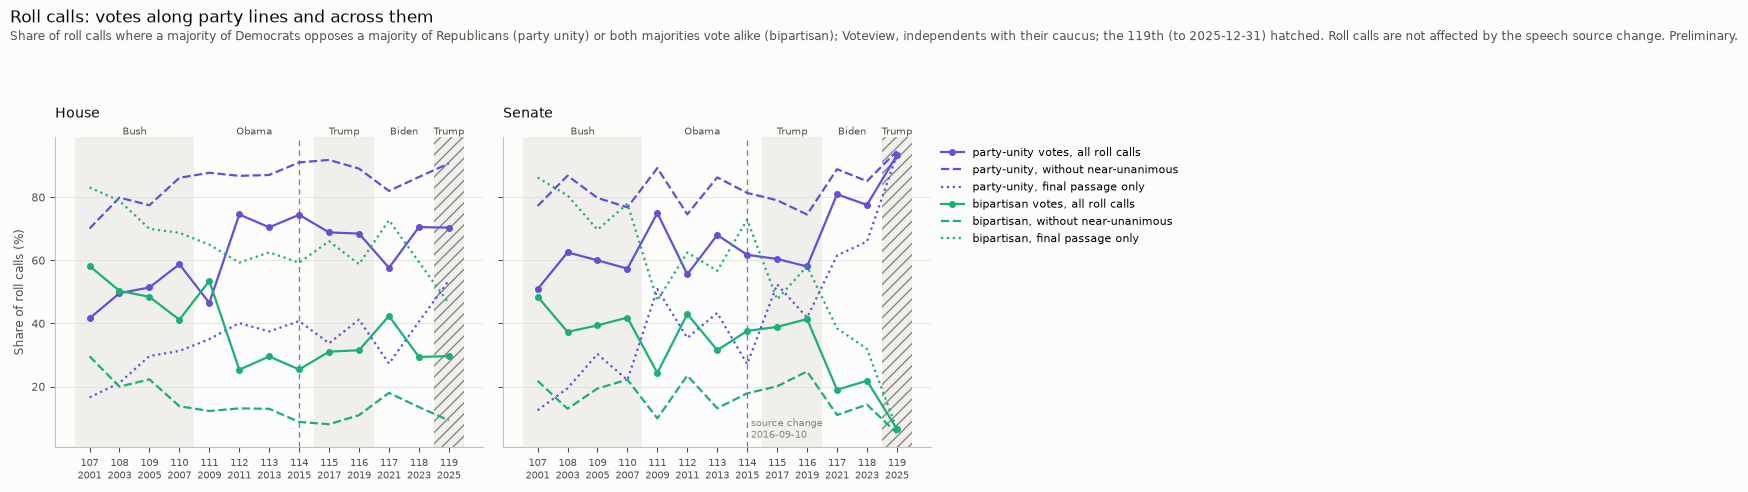

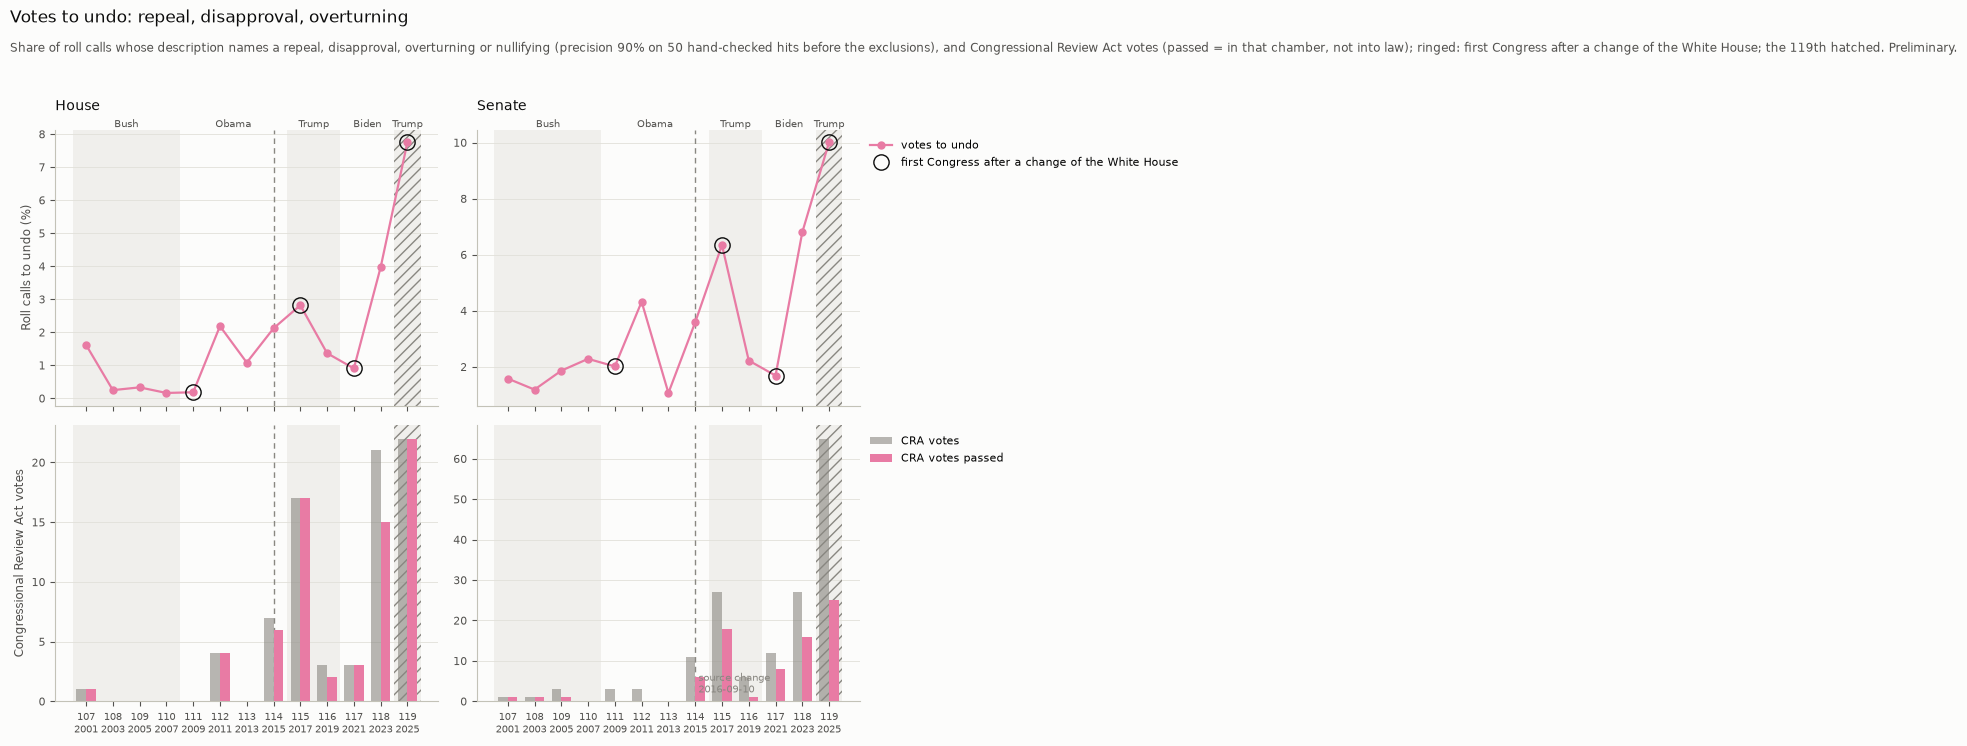

chamber                      H                                                                             S                                                               
variant         all roll calls final passage only without independents without near-unanimous all roll calls final passage only without independents without near-unanimous
congress_number                                                                                                                                                            
107                      0.416              0.166                0.416                  0.701          0.509              0.125                0.510                  0.772
108                      0.496              0.212                0.496                  0.799          0.625              0.194                0.621                  0.868
109                      0.514              0.297                0.515                  0.775          0.600              0.303                0.603                  0.798
110                      0.588              0.313                0.588                  0.862          0.574              0.221                0.572                  0.768
111                      0.465              0.350                0.465                  0.877          0.750              0.509                0.750                  0.892
112                      0.745              0.401                0.745                  0.868          0.556              0.354                0.553                  0.746
113                      0.705              0.375                0.705                  0.871          0.680              0.433                0.680                  0.863
114                      0.744              0.408                0.744                  0.910          0.618              0.271                0.618                  0.814
115                      0.688              0.337                0.688                  0.918          0.604              0.524                0.601                  0.790
116                      0.685              0.412                0.685                  0.891          0.581              0.419                0.582                  0.745
117                      0.576              0.273                0.576                  0.820          0.809              0.615                0.809                  0.889
118                      0.705              0.405                0.705                  0.864          0.776              0.660                0.779                  0.851
119                      0.704              0.536                0.704                  0.907          0.933              0.935                0.935                  0.946

,chamber,measure,kind,r_ci,n_congresses
0,H,share_party_unity,raw,"+0.54 [-0.05, +0.85]",12
1,H,share_party_unity,detrended,"+0.02 [-0.59, +0.61]",12
2,S,share_party_unity,raw,"+0.62 [+0.07, +0.88]",12
3,S,share_party_unity,detrended,"+0.25 [-0.41, +0.74]",12
4,H,share_bipartisan,raw,"-0.53 [-0.85, +0.06]",12
5,H,share_bipartisan,detrended,"-0.02 [-0.61, +0.59]",12
6,S,share_bipartisan,raw,"-0.63 [-0.88, -0.08]",12
7,S,share_bipartisan,detrended,"-0.27 [-0.75, +0.40]",12


congress_number,107,108,109,110,111,112,113,114,115,116,117,118,119
n_resolutions_voted,1,1,2,0,3,5,0,6,20,6,11,24,33
n_resolutions_passed_a_chamber,1,1,1,0,0,2,0,6,19,2,8,20,26


,congress_number,chamber,n_votes,n_undo,n_cra,n_cra_passed,share_undo,n_final,n_undo_final,share_undo_final,first_after_wh_change,complete,n_resolutions_voted,n_resolutions_passed_a_chamber
0,107,H,990,16,1,1,0.016,308,6,0.019,False,True,1,1
1,107,S,633,10,1,1,0.016,80,1,0.013,False,True,1,1
2,108,H,1218,3,0,0,0.002,345,1,0.003,False,True,1,1
3,108,S,675,8,1,1,0.012,72,1,0.014,False,True,1,1
4,109,H,1210,4,0,0,0.003,310,2,0.006,False,True,2,1
5,109,S,645,12,3,1,0.019,66,2,0.030,False,True,2,1
6,110,H,1865,3,0,0,0.002,470,0,0.000,False,True,0,0
7,110,S,657,15,0,0,0.023,68,0,0.000,False,True,0,0
8,111,H,1647,3,0,0,0.002,454,2,0.004,True,True,3,0
9,111,S,696,14,3,0,0.020,55,1,0.018,True,True,3,0


In [22]:
sheet = read_keyword_check(check_path)
precision = keyword_precision({"rollcall_undo": sheet})
display(precision)
CRA_PASSED = ("Passed", "Bill Passed", "Joint Resolution Passed")  # confirmed at HALT 2
flagged = flag_rollcall_undo(rollcalls, passed=CRA_PASSED)
flagged["final_passage"] = is_final_passage(flagged)
ids = flagged["congress_number"].astype(str) + "-" + flagged["chamber"] + "-" + flagged["rollnumber"].astype(str)
after = sheet.assign(hit_after_exclusions=sheet["rollcall"].map(dict(zip(ids, flagged["undo"]))))
print("Hand-checked hits after the exclusions (rows: correct; columns: still a hit):")
display(pd.crosstab(after["correct"], after["hit_after_exclusions"]))
assert not after.loc[after["correct"] == 0, "hit_after_exclusions"].any(), "an excluded false hit is still a hit"
assert after.loc[after["correct"] == 1, "hit_after_exclusions"].all(), "an exclusion removed a correct hit"
print(f"Final passage votes: {flagged['final_passage'].sum():,} "
      f"({flagged.groupby('chamber')['final_passage'].sum().to_dict()})")
final = is_final_passage(party_votes)
variants = {
    "all roll calls": rollcall_summary(party_votes),
    "without near-unanimous": rollcall_summary(party_votes[~party_votes["near_unanimous"]]),
    "final passage only": rollcall_summary(party_votes[final]),
    "without independents": rollcall_summary(party_votes_ind),
}
unity = pd.concat([t.assign(variant=name) for name, t in variants.items()], ignore_index=True)
unity["complete"] = unity["congress_number"] <= LAST_COMPLETE
fig = plot_rollcall_lines(
    unity,
    [("share_party_unity", "all roll calls", "party-unity votes, all roll calls"),
     ("share_party_unity", "without near-unanimous", "party-unity, without near-unanimous"),
     ("share_party_unity", "final passage only", "party-unity, final passage only"),
     ("share_bipartisan", "all roll calls", "bipartisan votes, all roll calls"),
     ("share_bipartisan", "without near-unanimous", "bipartisan, without near-unanimous"),
     ("share_bipartisan", "final passage only", "bipartisan, final passage only")],
    "Roll calls: votes along party lines and across them",
    subtitle=(f"Share of roll calls where a majority of Democrats opposes a majority of Republicans (party unity) or both "
              f"majorities vote alike (bipartisan); Voteview, independents with their caucus; the {LAST_CONGRESS}th "
              f"(to 2025-12-31) hatched. Roll calls are not affected by the speech source change. Preliminary."),
    incomplete=INCOMPLETE,
)
keep(fig, "deepdive_rollcall_party_unity")

gaps = party_gap(cell_means(df, "ideology"))[["congress_number", "chamber", "gap"]]
joined = gaps.merge(variants["all roll calls"], on=["congress_number", "chamber"], validate="one_to_one")
joined["complete"] = joined["congress_number"] <= LAST_COMPLETE
correlation = pd.concat([measure_gap_correlation(joined, c) for c in ("share_party_unity", "share_bipartisan")],
                        ignore_index=True)
undo = rollcall_undo_summary(flagged)
undo["complete"] = undo["congress_number"] <= LAST_COMPLETE
resolutions = (cra_resolutions(flagged).set_index("congress_number")
               .reindex(sorted(flagged["congress_number"].unique()), fill_value=0).reset_index())
undo = undo.merge(resolutions, on="congress_number", how="left", validate="many_to_one")
fig = plot_rollcall_undo(
    undo, "Votes to undo: repeal, disapproval, overturning",
    subtitle=(f"Share of roll calls whose description names a repeal, disapproval, overturning or nullifying (precision "
              f"{100 * precision['precision'].iloc[0]:.0f}% on 50 hand-checked hits before the exclusions), and Congressional "
              f"Review Act votes (passed = in that chamber, not into law); "
              f"ringed: first Congress after a change of the White House; the {LAST_CONGRESS}th hatched. Preliminary."),
    incomplete=INCOMPLETE,
)
keep(fig, "deepdive_rollcall_undo")
tables |= {"rollcall_party_unity": unity, "rollcall_gap_correlation": correlation,
           "rollcall_undo": undo.assign(precision=precision["precision"].iloc[0])}
display(unity.pivot_table(index="congress_number", columns=["chamber", "variant"],
                          values="share_party_unity").round(3))
display(correlation.assign(r_ci=with_ci(correlation, "r", 2))[["chamber", "measure", "kind", "r_ci", "n_congresses"]])
display(resolutions.set_index("congress_number").T)
undo

**Reading it (10).** Preliminary and descriptive. Which roll calls happen is decided by the
majority: bills without a majority often never come to a vote, and many party-unity votes
are the minority's amendments and motions.

- **Roll calls along party lines rose.** Party-unity votes: House 41.6% of roll calls in the
  107th, 69–75% from the 112th on (58% in the 117th); Senate 50.9% → 77.6% in the 118th and 93.3% in 2025.
  Among final passage votes the rise is steeper (House 16.6% → 40.5% in the 118th, 53.6% in
  2025; Senate 12.5% → 66.0%, 93.5% in 2025). Without near-unanimous votes the levels are
  higher (House 70% → 86–92%). Leaving out the independents changes nothing visible.
- **Association with the speech gap:** both rise over time, so the raw correlation is
  positive (House +0.54 [−0.05, +0.85], Senate +0.62 [+0.07, +0.88]); once a linear
  trend is removed from both it is not clear (House +0.02 [−0.59, +0.61], Senate +0.25
  [−0.41, +0.74]). Twelve Congresses only.
- **Votes to undo** (precision 90% before the exclusions) stay at 0.2–4.3% of roll calls up
  to the 117th, then rise: 118th House 4.0%, Senate 6.8%; 2025 House 7.8%, Senate 10.0%.
  Of the four first Congresses after a change of the White House, the share rose after
  2017 (House 2.8%, Senate 6.3%) and in 2025, not after 2009 or 2021.
- **Congressional Review Act** roll calls: 0–7 per Congress up to the 113th, then 18
  (114th), 44 (115th), 9, 15, 48 (118th) and 87 in 2025. Distinct resolutions passed by at
  least one chamber: 19 in the 115th, 20 in the 118th, 26 in 2025. **Passing one chamber
  is not becoming law:** in the 118th, 11 votes to override a presidential veto of such
  resolutions failed (6 House, 5 Senate).
- Senate final-passage shares of undo votes look large (e.g. 61.7% in the 118th) because
  the Senate holds few final passage votes (30–80 per Congress) and CRA joint resolutions
  are among them.

## Saving the figures and tables

In [23]:
# Added with 4b and 4c (2026-11-06): every output that already exists is compared with
# what this run made, and none is rewritten. A figure counts as the same only if its bytes
# are equal. A table counts as the same if its columns, shape and text are equal and every
# number agrees to floating-point noise (relative 1e-12, absolute 1e-15): separate runs
# differ in the last bit (decided 2026-11-06). Any other difference stops here, before
# anything is written.
import hashlib
import io

from src.plots import SURFACE

RTOL, ATOL = 1e-12, 1e-15


def digest(content):
    return hashlib.sha256(content).hexdigest()


def table_difference(path, table):
    """None if the table differs beyond noise, else the largest absolute difference."""
    disk = pd.read_csv(path)
    new = pd.read_csv(io.StringIO(table.to_csv(index=False)))
    numeric = list(disk.select_dtypes("number").columns)
    if list(disk.columns) != list(new.columns) or disk.shape != new.shape:
        return None
    if list(new.select_dtypes("number").columns) != numeric:
        return None
    text = [c for c in disk.columns if c not in numeric]
    if not disk[text].astype(str).equals(new[text].astype(str)):
        return None
    a, b = disk[numeric].to_numpy(float), new[numeric].to_numpy(float)
    if not np.isclose(a, b, rtol=RTOL, atol=ATOL, equal_nan=True).all():
        return None
    gaps = np.abs(a - b)
    return float(np.nanmax(gaps)) if np.isfinite(gaps).any() else 0.0


identical, within_noise, differs = [], [], []
for name, table in list(tables.items()):
    path = METRICS_DIR / f"deepdive_{name}_{RUN}.csv"
    if path.exists():
        if digest(path.read_bytes()) == digest(table.to_csv(index=False).encode()):
            identical.append(path.name)
        else:
            gap = table_difference(path, table)
            (differs if gap is None else within_noise).append(path.name if gap is None else (path.name, gap))
        del tables[name]
for name, fig in list(figures.items()):
    path = PLOTS_DIR / f"{name}.png"
    if path.exists():
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=200, bbox_inches="tight", facecolor=SURFACE)  # as save_figure
        (identical if digest(path.read_bytes()) == digest(buffer.getvalue()) else differs).append(path.name)
        del figures[name]
print(f"{len(identical)} existing outputs byte-identical; {len(within_noise)} equal to floating-point noise "
      "(kept as they are, largest absolute difference):")
for file, gap in within_noise:
    print(f"  {file}: {gap:.1e}")
if differs:
    raise RuntimeError(f"these outputs differ from the files on disk, nothing written: {differs}")
print("To write:", [*tables], [*figures])

27 existing outputs byte-identical; 3 equal to floating-point noise (kept as they are, largest absolute difference):
  deepdive_chamber_flip_did_20261018T122536Z.csv: 1.1e-16
  deepdive_swing_states_own_margin_20261018T122536Z.csv: 2.2e-16
  deepdive_cohort_vs_continuing_20261018T122536Z.csv: 1.1e-16
To write: ['power_ladder', 'power_ladder_cells', 'power_constellations', 'post_election_windows', 'post_election_losers', 'post_election_effects', 'post_election_cell_sizes'] ['deepdive_power_ladder', 'deepdive_post_election']


In [24]:
print("Run times (minutes):", {k: round(v / 60, 1) for k, v in timings.items()})
targets = {PLOTS_DIR / f"{name}.png": fig for name, fig in figures.items()}
paths = {METRICS_DIR / f"deepdive_{name}_{RUN}.csv": table for name, table in tables.items()}
existing = [p for p in [*targets, *paths] if p.exists()]
if existing:
    raise RuntimeError(f"would overwrite {[p.name for p in existing]}: ask first")
for path, fig in targets.items():
    save_figure(fig, path.stem)
    print(path.relative_to(ROOT))
for path, table in paths.items():
    table.to_csv(path, index=False)
    print(path.relative_to(ROOT))

Run times (minutes): {'step decomposition bootstrap': 12.4, 'corpus keyword pass': 9.7, 'centrist bootstrap': 1.2, 'loading Voteview votes': 0.2}


results/plots/deepdive_power_ladder.png


results/plots/deepdive_post_election.png
results/metrics/deepdive_power_ladder_20261018T122536Z.csv
results/metrics/deepdive_power_ladder_cells_20261018T122536Z.csv
results/metrics/deepdive_power_constellations_20261018T122536Z.csv
results/metrics/deepdive_post_election_windows_20261018T122536Z.csv
results/metrics/deepdive_post_election_losers_20261018T122536Z.csv
results/metrics/deepdive_post_election_effects_20261018T122536Z.csv
results/metrics/deepdive_post_election_cell_sizes_20261018T122536Z.csv
